# Gender, innovation and technology adoption in Peruvian firms, 2017 vs 2023
### Econometric Analysis of Firm Data (KAN-CEAPV2505U): analysis notebook

**Research question.** Are firms run by a female top manager less likely to innovate and adopt technology, and did that gap change over the COVID period (2017 → 2023)?

**Hypotheses**
- **H1:** female-led firms are less likely to innovate or adopt technology, *conditional on firm characteristics*.
- **H2:** the gap changed between the pre-COVID (2017) and post-COVID (2023) waves.
- **H3:** a large part of the *raw* gap comes from differences in firm characteristics (sector, size, age...) rather than from manager gender itself.

**How the notebook is organised.** Each step answers a weakness of the step before. That progression is the econometric argument of the paper, and it matches the course learning objective of *detecting when OLS is not adequate and choosing a better model*.

| Part | Method | What it adds | Course week |
|---|---|---|---|
| 1 | Descriptive statistics, raw difference-in-differences | What the data look like | 36 |
| 2 | Linear probability model (OLS) | Baseline with controls; clustered SEs | 36–38 |
| 3 | Probit and logit (maximum likelihood) | Fixes LPM problems with binary outcomes; partial effects; interaction effects | 43–45 |
| 4 | Omitted variables: proxy variable and IV | Is `female_mgr` endogenous? | 39–40 |
| 5 | Panel data: first differences / fixed effects / random effects | Removes time-constant unobserved firm heterogeneity | 41–43 |
| 6 | Oaxaca–Blinder decomposition | How much of the raw gap is explained by characteristics (H3) | 45 |
| 7 | Assumption checks for every model | Which assumptions hold, which are violated, what we do about it | all |
| 8 | Robustness: weights, ownership, multiple testing, survival | Do the conclusions survive? | all |
| 9 | Summary | What to write in the paper | |

**Data.** World Bank Enterprise Surveys, Peru formal sector, 2017–2023 panel file, cleaned by `01_clean_peru.py`:
- `peru_pooled.csv`: all 1,990 firm-year observations (1,003 in 2017 and 987 in 2023)
- `peru_panel.csv`: the 358 firms interviewed in both waves

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from linearmodels.panel import PanelOLS, RandomEffects
from linearmodels.iv import IV2SLS

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.width", 160)

import os
os.makedirs("paper/tables", exist_ok=True)
os.makedirs("paper/figures", exist_ok=True)

df = pd.read_csv("peru_pooled.csv")
pan = pd.read_csv("peru_panel.csv")

# Outcomes (all binary: 1 = yes, 0 = no)
OUTCOMES = {
    "new_product":   "New product/service",
    "process_innov": "Process innovation",
    "rd":            "R&D spending",
    "website":       "Own website",
    "quality_cert":  "Quality certification",
}

# Bootstrap replications for the probit/logit standard errors.
# 199 = final version used in the paper (lower it, e.g. to 49, while experimenting).
REPS = 199

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

print(f"Pooled sample: {len(df)} observations | Panel: {pan.panelid.nunique()} firms x 2 waves")

Pooled sample: 1990 observations | Panel: 358 firms x 2 waves


### Variables used

| Variable | Definition | Raw question |
|---|---|---|
| `female_mgr` | 1 if the top manager is a woman | b7a |
| `post` | 1 if 2023 wave (after COVID), 0 if 2017 | year |
| `female_mgr_x_post` | interaction `female_mgr × post` | |
| `new_product`, `process_innov`, `rd`, `website`, `quality_cert` | outcomes (0/1) | h1, h5, h8, c22b, b8 |
| `ln_emp` | log of permanent full-time employees (size) | l1 |
| `ln_age` | log(1 + firm age) | b5 |
| `mgr_exp` | top manager's years of experience in the sector | b7 |
| `exporter` | direct exports ≥ 10% of sales | d3c |
| `foreign_owned` | foreign ownership ≥ 10% | b2b |
| `multi_estab` | establishment belongs to a larger firm | a7 |
| `sector`, `region` | 7 sampling sectors, 5 regions | a4a, a2 |
| `female_own_any` | at least one female owner | b4 |
| `panelid` | firm identifier, constant across waves | |

---
# Part 1: Descriptive analysis

## 1.1 Who are the female-led firms?

Before any regression, compare the two groups. For each variable we report the mean for male-led and female-led firms and test whether the difference is zero with a **Welch t-test** (a two-sample t-test that does not assume equal variances):

$$
t = \frac{\bar x_F - \bar x_M}{\sqrt{\dfrac{s_F^2}{n_F} + \dfrac{s_M^2}{n_M}}}
$$

**Why this matters.** If female-led firms differ systematically in characteristics that *also* affect innovation (size, sector, age...), a raw comparison of innovation rates mixes the effect of manager gender with the effect of those characteristics. That is **omitted variable bias**, and it is the reason for every regression that follows.

In [2]:
summary_vars = {
    **OUTCOMES,
    "employees": "Employees (permanent full-time)",
    "firm_age": "Firm age (years)",
    "mgr_exp": "Manager experience (years)",
    "exporter": "Exporter (>=10% of sales)",
    "foreign_owned": "Foreign owned (>=10%)",
    "multi_estab": "Part of larger firm",
    "manufacturing": "Manufacturing",
    "female_worker_share": "Female share of workforce",
    "female_own_any": "Any female owner",
}
rows = []
for var, label in summary_vars.items():
    m = df.loc[df.female_mgr == 0, var].dropna()
    f = df.loc[df.female_mgr == 1, var].dropna()
    t, p = stats.ttest_ind(f, m, equal_var=False)
    rows.append({"Variable": label, "Male-led": m.mean(), "Female-led": f.mean(),
                 "Diff (F-M)": f.mean() - m.mean(), "p-value": p, "": stars(p)})
table1 = pd.DataFrame(rows).set_index("Variable")
print(f"Male-led N = {(df.female_mgr==0).sum()},  Female-led N = {(df.female_mgr==1).sum()}")
table1

Male-led N = 1588,  Female-led N = 402


,Male-led,Female-led,Diff (F-M),p-value,
Variable,,,,,
New product/service,0.671,0.617,-0.054,0.044,**
Process innovation,0.569,0.555,-0.014,0.611,
R&D spending,0.259,0.197,-0.063,0.006,***
Own website,0.743,0.683,-0.059,0.021,**
Quality certification,0.225,0.119,-0.106,0.000,***
Employees (permanent full-time),139.004,95.382,-43.623,0.167,
Firm age (years),23.802,21.185,-2.617,0.001,***
Manager experience (years),24.226,22.360,-1.866,0.003,***
Exporter (>=10% of sales),0.159,0.137,-0.023,0.248,


### Weighted descriptives

The survey over-samples large firms. Weighted means (using the sampling weight `wmedian`) describe the **population** of Peruvian formal firms; unweighted means describe the **sample**. Both are reported so the headline descriptives do not ignore the sampling design:

$$\bar x_w = \frac{\sum_i w_i x_i}{\sum_i w_i}$$

Weights are very unequal here, so we also report **Kish's effective sample size**, $n_{\text{eff}} = (\sum_i w_i)^2 / \sum_i w_i^2$: the number of equally weighted observations that would give the same precision as the weighted sample.

In [3]:
def wmean(x, w):
    ok = x.notna()
    return np.average(x[ok], weights=w[ok])

rows = []
for var, label in summary_vars.items():
    m, f = df[df.female_mgr == 0], df[df.female_mgr == 1]
    rows.append({"Variable": label, "Male-led (w)": wmean(m[var], m["weight"]),
                 "Female-led (w)": wmean(f[var], f["weight"])})
table1w = pd.DataFrame(rows).set_index("Variable")
table1w["Diff (w)"] = table1w["Female-led (w)"] - table1w["Male-led (w)"]

kish = df["weight"].sum() ** 2 / (df["weight"] ** 2).sum()
print(f"Kish effective sample size: {kish:.0f} of {len(df)} observations;  max weight / mean weight = {df.weight.max()/df.weight.mean():.0f}")
pd.concat([table1[["Male-led", "Female-led", "Diff (F-M)"]], table1w], axis=1)

Kish effective sample size: 161 of 1990 observations;  max weight / mean weight = 34


,Male-led,Female-led,Diff (F-M),Male-led (w),Female-led (w),Diff (w)
Variable,,,,,,
New product/service,0.671,0.617,-0.054,0.645,0.615,-0.030
Process innovation,0.569,0.555,-0.014,0.620,0.652,0.032
R&D spending,0.259,0.197,-0.063,0.231,0.181,-0.050
Own website,0.743,0.683,-0.059,0.794,0.755,-0.040
Quality certification,0.225,0.119,-0.106,0.141,0.057,-0.084
Employees (permanent full-time),139.004,95.382,-43.623,54.943,42.756,-12.187
Firm age (years),23.802,21.185,-2.617,23.313,21.342,-1.971
Manager experience (years),24.226,22.360,-1.866,26.134,19.765,-6.369
Exporter (>=10% of sales),0.159,0.137,-0.023,0.087,0.050,-0.037


**Reading the table.**
- Female-led firms are about 20% of the sample.
- In the raw data they are **less likely** to have a quality certificate (about 11 percentage points less), to spend on R&D, to have a website and to introduce new products.
- They are also **different in other ways**: younger, less often foreign-owned or part of a larger firm, more often in services, and with more women in the workforce.
- The second set of differences is the warning sign. Part of the innovation gap may come from *these* characteristics, not from the manager's gender.

## 1.2 Raw difference-in-differences

To see whether the gap changed over the COVID period, compute four means for each outcome and take the **double difference**:

$$
\text{DiD} = \underbrace{(\bar y_{F,2023} - \bar y_{F,2017})}_{\text{change for female-led}} \; - \; \underbrace{(\bar y_{M,2023} - \bar y_{M,2017})}_{\text{change for male-led}}
$$

A positive DiD means female-led firms **caught up** (the gap narrowed). The male-led firms act as the comparison group: their change absorbs everything that happened to *all* firms between 2017 and 2023 (COVID, the economic cycle, a general digitalisation trend).

The key assumption is **parallel trends**: without COVID, female- and male-led firms would have changed by the same amount. With only two waves this can't be tested, so it has to be argued in the paper.

In [4]:
means = df.groupby(["female_mgr", "post"])[list(OUTCOMES)].mean()
rows = []
for var, label in OUTCOMES.items():
    m17, m23 = means.loc[(0, 0), var], means.loc[(0, 1), var]
    f17, f23 = means.loc[(1, 0), var], means.loc[(1, 1), var]
    rows.append({"Outcome": label, "Male 2017": m17, "Male 2023": m23,
                 "Female 2017": f17, "Female 2023": f23,
                 "Gap 2017": f17 - m17, "Gap 2023": f23 - m23,
                 "Raw DiD": (f23 - f17) - (m23 - m17)})
table2 = pd.DataFrame(rows).set_index("Outcome")
table2

,Male 2017,Male 2023,Female 2017,Female 2023,Gap 2017,Gap 2023,Raw DiD
Outcome,,,,,,,
New product/service,0.654,0.690,0.610,0.623,-0.044,-0.066,-0.022
Process innovation,0.519,0.622,0.462,0.636,-0.056,0.013,0.069
R&D spending,0.275,0.242,0.198,0.195,-0.077,-0.047,0.031
Own website,0.692,0.797,0.599,0.757,-0.093,-0.040,0.053
Quality certification,0.224,0.225,0.109,0.127,-0.115,-0.099,0.016


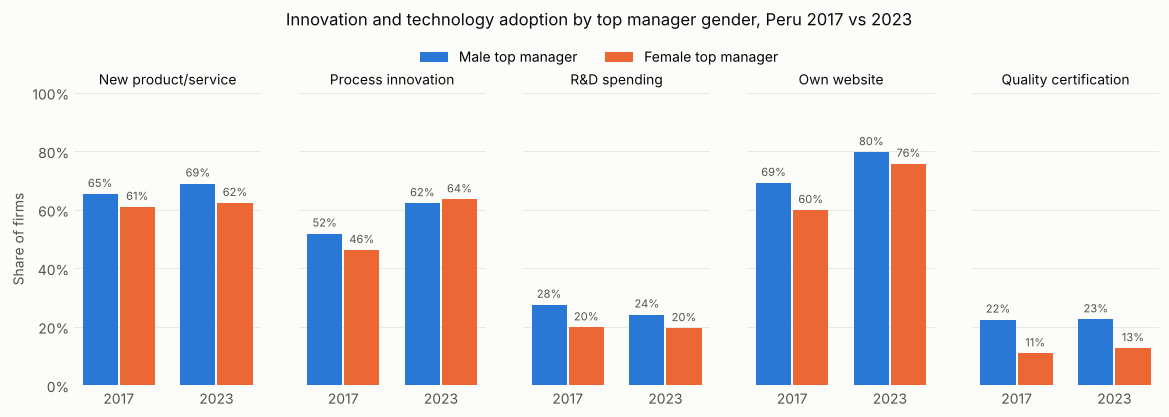

In [5]:
BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#fcfcfb"
fig, axes = plt.subplots(1, len(OUTCOMES), figsize=(14, 3.8), sharey=True, facecolor=SURFACE)
x, w = np.array([0, 1]), 0.36
for ax, (var, label) in zip(axes, OUTCOMES.items()):
    ax.set_facecolor(SURFACE)
    male = [means.loc[(0, 0), var], means.loc[(0, 1), var]]
    fem = [means.loc[(1, 0), var], means.loc[(1, 1), var]]
    b1 = ax.bar(x - w/2 - 0.01, male, w, color=BLUE, label="Male top manager")
    b2 = ax.bar(x + w/2 + 0.01, fem, w, color=ORANGE, label="Female top manager")
    for bars in (b1, b2):
        for b in bars:
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{b.get_height():.0%}",
                    ha="center", va="bottom", fontsize=8, color=MUTED)
    ax.set_title(label, fontsize=10, color=INK)
    ax.set_xticks(x, ["2017", "2023"])
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="y", color="#e6e5e1", linewidth=0.6); ax.set_axisbelow(True)
    for s in ax.spines.values(): s.set_visible(False)
axes[0].set_ylabel("Share of firms", color=MUTED)
fig.legend(handles=[b1, b2], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.03))
fig.suptitle("Innovation and technology adoption by top manager gender, Peru 2017 vs 2023", y=1.1, color=INK)
fig.savefig("paper/figures/fig1_outcomes.pdf", bbox_inches="tight", facecolor=SURFACE)
plt.show()

**Reading the figure.** The gaps narrowed for process innovation, website and R&D. For process innovation, female-led firms even overtake male-led firms by 2023. But these are *raw* numbers: no controls, no standard errors. The next parts check whether the patterns survive once firm characteristics are held constant and sampling uncertainty is accounted for.

---
# Part 2: Linear probability model (LPM)

## 2.1 The model

For each binary outcome $y_{it}$ (firm $i$, wave $t$) we estimate by OLS:

$$
y_{it} = \beta_0 + \beta_1\, \text{Female}_{it} + \beta_2\, \text{Post}_t + \beta_3\, (\text{Female}_{it} \times \text{Post}_t) + \mathbf{x}_{it}'\boldsymbol\gamma + u_{it}
$$

where $\mathbf{x}_{it}$ contains the controls (log employees, log firm age, manager experience, exporter, foreign-owned, multi-establishment, sector dummies, region dummies).

Because $y$ is 0/1, its expected value is a probability: $E(y \mid \mathbf{x}) = P(y=1 \mid \mathbf{x})$. Each coefficient is therefore a change in **probability**, measured in percentage points.

**What each coefficient means.** Substitute Post = 0 and Post = 1:

| | 2017 (Post = 0) | 2023 (Post = 1) |
|---|---|---|
| Male-led | $\beta_0 + \mathbf{x}'\boldsymbol\gamma$ | $\beta_0 + \beta_2 + \mathbf{x}'\boldsymbol\gamma$ |
| Female-led | $\beta_0 + \beta_1 + \mathbf{x}'\boldsymbol\gamma$ | $\beta_0 + \beta_1 + \beta_2 + \beta_3 + \mathbf{x}'\boldsymbol\gamma$ |

- $\beta_1$ = female–male gap **in 2017**, holding controls fixed → tests **H1**
- $\beta_2$ = change for male-led firms between 2017 and 2023
- $\beta_3$ = how much the gap **changed** by 2023 → the regression version of the DiD, tests **H2**
- the gap in 2023 is $\beta_1 + \beta_3$

## 2.2 Why clustered standard errors?

The usual OLS standard errors assume errors are independent across observations. Here the 358 panel firms appear **twice**, and the same firm's errors in 2017 and 2023 are almost certainly correlated (persistent management quality, for example). Treating them as independent overstates the amount of information and makes standard errors too small.

The **cluster-robust** variance estimator allows any correlation *within* a firm and any heteroskedasticity:

$$
\widehat{\text{Var}}(\hat{\boldsymbol\beta}) = (X'X)^{-1} \Big( \sum_{g=1}^{G} X_g' \hat{\mathbf u}_g \hat{\mathbf u}_g' X_g \Big) (X'X)^{-1}
$$

where $g$ indexes firms (clusters) and $\hat{\mathbf u}_g$ is the vector of residuals of firm $g$.

It also handles a built-in problem of the LPM: **heteroskedasticity by construction**. Since $y$ is Bernoulli,

$$
\text{Var}(y \mid \mathbf{x}) = p(\mathbf x)\,[1 - p(\mathbf x)],
$$

which changes with $\mathbf x$. The homoskedasticity assumption of OLS (MLR.5) is violated *by definition*. The OLS coefficients are still unbiased, but the usual standard errors are wrong, so robust (here, cluster-robust) standard errors are mandatory.

In [6]:
CONTROLS = "ln_emp + ln_age + mgr_exp + exporter + foreign_owned + multi_estab + C(sector) + C(region)"
RHS = "female_mgr + post + female_mgr_x_post + " + CONTROLS
BASE_COLS = ["female_mgr", "post", "female_mgr_x_post", "ln_emp", "ln_age", "mgr_exp",
             "exporter", "foreign_owned", "multi_estab", "sector", "region", "panelid"]

lpm_res, samples = {}, {}
for var in OUTCOMES:
    d = df[[var] + BASE_COLS].dropna().reset_index(drop=True)
    samples[var] = d
    lpm_res[var] = smf.ols(f"{var} ~ {RHS}", d).fit(cov_type="cluster", cov_kwds={"groups": d["panelid"]})

# Full output for one outcome, to see what statsmodels reports
print(lpm_res["quality_cert"].summary().tables[1])

                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -0.1177      0.057     -2.070      0.038      -0.229      -0.006
C(sector)[T.garments]          -0.1226      0.038     -3.205      0.001      -0.198      -0.048
C(sector)[T.hotels]            -0.1708      0.035     -4.902      0.000      -0.239      -0.103
C(sector)[T.other_manuf]       -0.0070      0.031     -0.224      0.823      -0.069       0.055
C(sector)[T.other_services]    -0.0892      0.029     -3.084      0.002      -0.146      -0.033
C(sector)[T.retail]            -0.1153      0.029     -3.938      0.000      -0.173      -0.058
C(sector)[T.textiles]          -0.1495      0.040     -3.751      0.000      -0.228      -0.071
C(region)[T.Chiclayo]          -0.0729      0.025     -2.921      0.003      -0.122      -0.024
C(region)[T.Lima]              -0.0040  

**How to read this output (quality certification).**
- `female_mgr`: the 2017 gap after controls. Compare it with the raw gap of about −11 pp in Table 1: it shrinks by roughly two thirds and is no longer significant. Most of the raw gap is explained by the controls.
- `ln_emp`: larger firms are much more likely to be certified. This is the strongest predictor, and female-led firms are smaller on average, which is exactly the omitted-variable channel from Part 1.
- `female_mgr_x_post`: the change in the gap, small and insignificant.

In [7]:
rows = []
for var, label in OUTCOMES.items():
    r = lpm_res[var]
    rows.append({"Outcome": label,
                 "Female (2017 gap)": f"{r.params.female_mgr:.3f}{stars(r.pvalues.female_mgr)} ({r.bse.female_mgr:.3f})",
                 "Post": f"{r.params.post:.3f}{stars(r.pvalues.post)} ({r.bse.post:.3f})",
                 "Female x Post": f"{r.params.female_mgr_x_post:.3f}{stars(r.pvalues.female_mgr_x_post)} ({r.bse.female_mgr_x_post:.3f})",
                 "R2": round(r.rsquared, 3), "N": int(r.nobs)})
print("LPM, firm-clustered SEs in parentheses. *** p<.01 ** p<.05 * p<.10")
pd.DataFrame(rows).set_index("Outcome")

LPM, firm-clustered SEs in parentheses. *** p<.01 ** p<.05 * p<.10


,Female (2017 gap),Post,Female x Post,R2,N
Outcome,,,,,
New product/service,-0.018 (0.038),0.085*** (0.024),-0.036 (0.052),0.066,1959
Process innovation,-0.010 (0.040),0.151*** (0.026),0.053 (0.053),0.069,1948
R&D spending,-0.031 (0.033),-0.011 (0.022),0.018 (0.044),0.091,1953
Own website,-0.030 (0.037),0.129*** (0.021),0.023 (0.046),0.156,1959
Quality certification,-0.032 (0.024),0.040** (0.018),-0.017 (0.034),0.271,1926


## 2.3 Joint test: does manager gender matter at all?

Each t-test looks at one coefficient. **H1 and H2 together** ask whether $\beta_1 = \beta_3 = 0$: manager gender has no effect in either wave. That is an **F-test** (here a Wald test with the clustered variance):

$$
H_0: \beta_1 = 0 \text{ and } \beta_3 = 0
$$

In [8]:
rows = []
for var, label in OUTCOMES.items():
    w = lpm_res[var].wald_test("female_mgr = 0, female_mgr_x_post = 0", scalar=True)
    gap23 = lpm_res[var].t_test("female_mgr + female_mgr_x_post = 0")
    rows.append({"Outcome": label, "F-stat (b1=b3=0)": w.statistic, "p-value": w.pvalue,
                 "Gap 2023 (b1+b3)": float(gap23.effect[0]), "p (gap 2023)": float(gap23.pvalue)})
joint_tbl = pd.DataFrame(rows).set_index("Outcome")
joint_tbl

,F-stat (b1=b3=0),p-value,Gap 2023 (b1+b3),p (gap 2023)
Outcome,,,,
New product/service,2.231,0.328,-0.055,0.148
Process innovation,1.421,0.491,0.043,0.248
R&D spending,1.063,0.588,-0.013,0.674
Own website,0.672,0.714,-0.007,0.829
Quality certification,5.636,0.060,-0.049,0.046


## 2.4 The LPM's main weakness: predictions outside [0, 1]

The LPM is a straight line, so nothing stops $\hat y = \mathbf x'\hat{\boldsymbol\beta}$ from falling below 0 or above 1, which is impossible for a probability. If many predictions fall outside [0, 1], the linear functional form is a poor approximation, and the constant partial effects it implies are suspicious (a +1 log-point size increase cannot raise a probability that is already 0.95 by 15 points).

In [9]:
rows = []
for var, label in OUTCOMES.items():
    fv = lpm_res[var].fittedvalues
    rows.append({"Outcome": label, "Predictions < 0": int((fv < 0).sum()), "Predictions > 1": int((fv > 1).sum()),
                 "Share outside [0,1]": ((fv < 0) | (fv > 1)).mean(), "Min fitted": fv.min(), "Max fitted": fv.max()})
oor_tbl = pd.DataFrame(rows).set_index("Outcome")
oor_tbl

,Predictions < 0,Predictions > 1,"Share outside [0,1]",Min fitted,Max fitted
Outcome,,,,,
New product/service,0,2,0.001,0.377,1.101
Process innovation,0,0,0.000,0.220,0.965
R&D spending,7,0,0.004,-0.051,0.674
Own website,0,144,0.074,0.279,1.348
Quality certification,285,1,0.148,-0.187,1.039


**Takeaway.** For quality certification (a rare outcome, about 20%) and website (a common one, about 75%), many predictions fall outside [0, 1]. The LPM works worst exactly when the probability is close to 0 or 1. This motivates **probit and logit**, which keep predictions inside [0, 1] by construction.

---
# Part 3: Probit and logit (limited dependent variable models)

## 3.1 The latent-variable model

Assume there is an unobserved **latent** variable, e.g. the net benefit of getting certified:

$$
y_{it}^* = \mathbf{z}_{it}'\boldsymbol\beta + e_{it}, \qquad y_{it} = \mathbb{1}[y_{it}^* > 0]
$$

The firm certifies ($y = 1$) when the net benefit is positive. Then

$$
P(y=1 \mid \mathbf z) = P(e > -\mathbf z'\boldsymbol\beta) = G(\mathbf z'\boldsymbol\beta)
$$

where $G$ is the CDF of $e$:
- **Probit:** $e \sim N(0,1)$, so $G(\cdot) = \Phi(\cdot)$, the standard normal CDF
- **Logit:** $e$ is standard logistic, so $G(\cdot) = \Lambda(\cdot) = \dfrac{e^{\,\cdot}}{1+e^{\,\cdot}}$

Because $G$ is a CDF, predicted probabilities always lie between 0 and 1, which solves the problem from 2.4.

## 3.2 Estimation by maximum likelihood (MLE)

The probability of observing firm $i$'s actual outcome is $G(\mathbf z_i'\boldsymbol\beta)^{y_i}\,[1-G(\mathbf z_i'\boldsymbol\beta)]^{1-y_i}$. MLE picks the $\boldsymbol\beta$ that maximises the log-likelihood of the whole sample:

$$
\ell(\boldsymbol\beta) = \sum_{i=1}^{n} \Big\{ y_i \log G(\mathbf z_i'\boldsymbol\beta) + (1-y_i) \log\big[1 - G(\mathbf z_i'\boldsymbol\beta)\big] \Big\}
$$

## 3.3 Coefficients are NOT partial effects

In the LPM, $\partial P / \partial x_j = \beta_j$. In probit/logit, by the chain rule,

$$
\frac{\partial P(y=1 \mid \mathbf z)}{\partial x_j} = g(\mathbf z'\boldsymbol\beta)\,\beta_j
$$

where $g = G'$ is the density. The effect depends on **where** the firm is: it is largest when $P \approx 0.5$ and small when $P$ is close to 0 or 1. The raw coefficient only tells you the **sign**.

To get one number comparable with the LPM we use the **average partial effect (APE)**: compute each firm's effect and average over the sample. For a **dummy** like Female, use the discrete change instead of the derivative:

$$
\text{APE}_{\text{Female}} = \frac{1}{n}\sum_{i=1}^n \Big[ G(\mathbf z_i'\hat{\boldsymbol\beta} \mid \text{Female}=1) - G(\mathbf z_i'\hat{\boldsymbol\beta} \mid \text{Female}=0) \Big]
$$

We evaluate this with Post = 0, so it is the **2017 gap**, directly comparable with $\beta_1$ in the LPM.

## 3.4 The interaction effect is NOT the interaction coefficient (Ai & Norton, 2003)

In the LPM, $\beta_3$ *is* the DiD. In a nonlinear model, the coefficient on $\text{Female}\times\text{Post}$ does not equal the change in the gap on the probability scale. It can even have the **wrong sign** or be insignificant when the true interaction effect is significant. The correct quantity is the double difference of predicted probabilities, averaged over firms:

$$
\text{DiD}_{\text{prob}} = \frac{1}{n}\sum_{i=1}^n \Big\{ \big[\hat P_i(1,1) - \hat P_i(1,0)\big] - \big[\hat P_i(0,1) - \hat P_i(0,0)\big] \Big\}
$$

where $\hat P_i(f, p)$ is firm $i$'s predicted probability with Female $= f$ and Post $= p$ (other characteristics at their actual values).

## 3.5 Standard errors: firm-cluster bootstrap

The APE and $\text{DiD}_{\text{prob}}$ are nonlinear functions of $\hat{\boldsymbol\beta}$, so their standard errors are not reported directly. We use a **cluster bootstrap**:
1. Draw 358 + 1,274 firms (all clusters) **with replacement**, keeping both waves of a panel firm together.
2. Re-estimate the model and recompute APE and $\text{DiD}_{\text{prob}}$.
3. Repeat `REPS` times; the standard deviation of the draws is the standard error.

Resampling whole firms preserves the within-firm correlation, the same logic as clustering in Part 2. (The alternative is the delta method; both are valid.)

In [10]:
def female_ape(res, data):
    # 2017 gap: switch Female 0 -> 1 for every firm, with Post = 0
    d1, d0 = data.copy(), data.copy()
    for d in (d1, d0):
        d["post"], d["female_mgr_x_post"] = 0, 0
    d1["female_mgr"], d0["female_mgr"] = 1, 0
    return (res.predict(d1) - res.predict(d0)).mean()

def did_effect(res, data):
    # Double difference of predicted probabilities (Ai & Norton)
    def avg_p(f, p):
        d = data.copy()
        d["female_mgr"], d["post"], d["female_mgr_x_post"] = f, p, f * p
        return res.predict(d).mean()
    return (avg_p(1, 1) - avg_p(1, 0)) - (avg_p(0, 1) - avg_p(0, 0))

def both_effects(res, data):
    return np.array([female_ape(res, data), did_effect(res, data)])

def cluster_bootstrap_se(fit_fn, stat_fn, data, reps=REPS, seed=1):
    rng = np.random.default_rng(seed)
    ids = data["panelid"].unique()
    rows_of = data.groupby("panelid").indices          # firm id -> row positions
    draws = []
    for _ in range(reps):
        picked = rng.choice(ids, len(ids), replace=True)
        sample = data.iloc[np.concatenate([rows_of[i] for i in picked])].reset_index(drop=True)
        try:
            draws.append(stat_fn(fit_fn(sample), sample))
        except Exception:
            continue
    return np.std(np.array(draws), axis=0, ddof=1)

In [11]:
# First, look at one probit to see raw coefficients vs partial effects
d = samples["quality_cert"]
probit_qc = smf.probit(f"quality_cert ~ {RHS}", d).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d["panelid"]})
logit_qc = smf.logit(f"quality_cert ~ {RHS}", d).fit(disp=0, cov_type="cluster", cov_kwds={"groups": d["panelid"]})

comp = pd.DataFrame({
    "LPM coef": lpm_res["quality_cert"].params[["female_mgr", "ln_emp", "exporter"]],
    "Probit coef": probit_qc.params[["female_mgr", "ln_emp", "exporter"]],
    "Logit coef": logit_qc.params[["female_mgr", "ln_emp", "exporter"]],
    "Probit APE (dy/dx)": probit_qc.get_margeff(at="overall", dummy=True).summary_frame().loc[["female_mgr", "ln_emp", "exporter"], "dy/dx"],
})
print("Quality certification: raw coefficients are on different scales; APEs are comparable with the LPM")
comp

Quality certification: raw coefficients are on different scales; APEs are comparable with the LPM


,LPM coef,Probit coef,Logit coef,Probit APE (dy/dx)
female_mgr,-0.032,-0.222,-0.400,-0.043
ln_emp,0.092,0.364,0.634,0.074
exporter,0.139,0.430,0.700,0.099


**Why the raw coefficients differ so much.** Probit coefficients are on the scale of a standard normal, logit coefficients on the scale of a logistic with variance $\pi^2/3$. A rule of thumb is logit ≈ 1.6 × probit ≈ 4 × LPM. Once converted to **APEs** they become comparable with the LPM again.

(The `get_margeff` APE for `female_mgr` here averages over both waves without updating the interaction term. The functions above handle the interaction properly, and their results are reported next.)

In [12]:
%%time
results = []
for var, label in OUTCOMES.items():
    d = samples[var]
    formula = f"{var} ~ {RHS}"
    r = lpm_res[var]
    for term, name in [("female_mgr", "Female (2017 gap)"), ("female_mgr_x_post", "Female x Post (DiD)")]:
        results.append({"Outcome": label, "Model": "LPM", "Effect": name,
                        "Estimate": r.params[term], "SE": r.bse[term], "p": r.pvalues[term]})
    for model_name, fn in [("Probit", smf.probit), ("Logit", smf.logit)]:
        fit = lambda data, fn=fn: fn(formula, data).fit(disp=0)
        res = fit(d)
        ests = both_effects(res, d)
        ses = cluster_bootstrap_se(fit, both_effects, d)
        for name, est, se in zip(["Female (2017 gap)", "Female x Post (DiD)"], ests, ses):
            p = 2 * (1 - stats.norm.cdf(abs(est / se)))
            results.append({"Outcome": label, "Model": model_name, "Effect": name, "Estimate": est, "SE": se, "p": p})

table3 = pd.DataFrame(results)
table3["Cell"] = table3.apply(lambda r: f"{r.Estimate:.3f}{stars(r.p)} ({r.SE:.3f})", axis=1)
table3_wide = table3.pivot_table(index=["Outcome", "Effect"], columns="Model", values="Cell", aggfunc="first")[["LPM", "Probit", "Logit"]]
table3_wide

CPU times: user 4min 8s, sys: 101 ms, total: 4min 8s
Wall time: 4min 13s


Model                                                 LPM          Probit           Logit
Outcome               Effect                                                             
New product/service   Female (2017 gap)    -0.018 (0.038)  -0.016 (0.035)  -0.017 (0.036)
                      Female x Post (DiD)  -0.036 (0.052)  -0.036 (0.047)  -0.035 (0.047)
Own website           Female (2017 gap)    -0.030 (0.037)  -0.014 (0.034)  -0.015 (0.033)
                      Female x Post (DiD)   0.023 (0.046)   0.004 (0.043)   0.001 (0.043)
Process innovation    Female (2017 gap)    -0.010 (0.040)  -0.009 (0.044)  -0.009 (0.044)
                      Female x Post (DiD)   0.053 (0.053)   0.051 (0.057)   0.049 (0.056)
Quality certification Female (2017 gap)    -0.032 (0.024)  -0.040 (0.026)  -0.040 (0.027)
                      Female x Post (DiD)  -0.017 (0.034)  -0.013 (0.035)  -0.008 (0.037)
R&D spending          Female (2017 gap)    -0.031 (0.033)  -0.032 (0.032)  -0.032 (0.032)
                      Female x Post (DiD)   0.018 (0.044)   0.021 (0.045)   0.018 (0.045)

**Interpretation of Table 3.**
1. **LPM, probit and logit agree** once everything is on the probability scale. This is common when the effects of interest are averages: the LPM approximates average effects well even when it does poorly on individual predictions. The paper can say: *"the LPM is preferred for its simplicity; probit and logit confirm the results and avoid predictions outside [0, 1]."*
2. **H1:** conditional on firm characteristics, the **2017** female–male gap is small (1–4 pp) and **not statistically significant** for any outcome. (The joint tests in 2.3 show that the 2023 gap in quality certification, −4.9 pp, *is* significant at 5%.)
3. **H2:** the change in the gap between 2017 and 2023 is not significant in the pooled cross-sections. The point estimates match the raw DiD in sign (process innovation +5 pp, for example), but the standard errors are about 5 pp, so the data can't distinguish these changes from zero.
4. **Power.** With only about 200 female-led firms per wave, effects smaller than about 10 pp are hard to detect. A null result does not prove there is no effect. This belongs in the discussion section.

---
# Part 4: Is `female_mgr` endogenous? Proxy variable and IV

## 4.1 The omitted variable problem

Suppose the true model includes an unobserved factor $q$, such as **managerial ability** or firm culture:

$$
y = \beta_0 + \beta_1\,\text{Female} + \mathbf x'\boldsymbol\gamma + \delta\, q + v
$$

If we omit $q$, the OLS estimate of $\beta_1$ converges to

$$
\text{plim}\,\hat\beta_1 = \beta_1 + \delta \cdot \frac{\text{Cov}(\text{Female}, q)}{\text{Var}(\text{Female})} \quad\text{(after partialling out } \mathbf x\text{)}.
$$

**Direction of the bias.** Two plausible stories:
- Women face higher barriers to becoming top managers, so those who make it are positively selected on ability: Cov > 0 with δ > 0, giving an **upward** bias (the female effect looks too good).
- Female-led firms are concentrated in less dynamic market niches not captured by our sector dummies: a **downward** bias.

The sign of the bias is ambiguous, which is why it should be addressed rather than assumed away.

## 4.2 Proxy variable: manager experience

A **proxy** for $q$ is an observed variable correlated with it. We use the top manager's years of sector experience. The proxy works if (Wooldridge 9.2):
1. **Redundancy:** once $q$ is controlled, the proxy has no effect of its own on $y$.
2. **Conditional on the proxy, $q$ is uncorrelated with the other regressors:** $E(q \mid \text{Female}, \mathbf x, \text{exp}) = E(q \mid \text{exp})$.

Assumption 2 is strong: experience captures only part of ability. In practice the test is **sensitivity**: if adding the proxy barely moves $\hat\beta_1$, the omitted factor it partly captures is not driving the result.

In [13]:
CTRL_NO_EXP = "post + ln_emp + ln_age + exporter + foreign_owned + multi_estab + C(sector) + C(region)"
rows = []
for var, label in OUTCOMES.items():
    d = df[[var, "female_mgr", "mgr_exp", "female_own_any", "post", "ln_emp", "ln_age", "exporter",
            "foreign_owned", "multi_estab", "sector", "region", "panelid"]].dropna().reset_index(drop=True)
    cl = {"groups": d["panelid"]}
    a = smf.ols(f"{var} ~ female_mgr + {CTRL_NO_EXP}", d).fit(cov_type="cluster", cov_kwds=cl)
    b = smf.ols(f"{var} ~ female_mgr + mgr_exp + {CTRL_NO_EXP}", d).fit(cov_type="cluster", cov_kwds=cl)
    rows.append({"Outcome": label,
                 "Female, no proxy": f"{a.params.female_mgr:.3f}{stars(a.pvalues.female_mgr)}",
                 "Female, with proxy": f"{b.params.female_mgr:.3f}{stars(b.pvalues.female_mgr)}",
                 "Manager exp. coef": f"{b.params.mgr_exp:.4f}{stars(b.pvalues.mgr_exp)}"})
print("LPM, pooled 2017+2023 (no interaction, to keep the comparison simple)")
proxy_tbl = pd.DataFrame(rows).set_index("Outcome")
proxy_tbl

LPM, pooled 2017+2023 (no interaction, to keep the comparison simple)


,"Female, no proxy","Female, with proxy",Manager exp. coef
Outcome,,,
New product/service,-0.036,-0.037,-0.0004
Process innovation,0.018,0.019,0.0009
R&D spending,-0.021,-0.020,0.0006
Own website,-0.019,-0.018,0.0004
Quality certification,-0.038**,-0.040**,-0.0012


**Reading the table.** The female coefficient barely changes when the proxy is added, and experience itself has a tiny coefficient. Within this data, manager experience is **not** the omitted factor driving the results. This rules out one channel, not every omitted variable; that is what Part 5 addresses.

## 4.3 Instrumental variables: is there a usable instrument?

IV needs a variable $z$ that satisfies:
1. **Relevance:** $\text{Cov}(z, \text{Female}) \neq 0$, testable with the first-stage F-statistic (rule of thumb F > 10).
2. **Exogeneity (exclusion):** $\text{Cov}(z, u) = 0$. $z$ affects $y$ *only* through Female. This is **not testable** and must be argued.

With one instrument, the 2SLS estimator is

$$
\hat\beta_{1}^{IV} = \frac{\widehat{\text{Cov}}(z, y)}{\widehat{\text{Cov}}(z, \text{Female})} \quad\text{(after partialling out } \mathbf{x}\text{)}.
$$

**Candidate: a female owner (`female_own_any`).** Women owners are much more likely to appoint a woman as top manager, so relevance is very likely to hold. **But exclusion is doubtful:** female owners may affect innovation *directly* (through investment, risk preferences or access to credit), not only by choosing the manager. We estimate it **for illustration** and to show the method, and we report it as unreliable rather than as a causal estimate. The discussion matters more than the number here.

In [14]:
rows = []
for var, label in OUTCOMES.items():
    d = df[[var, "female_mgr", "mgr_exp", "female_own_any", "post", "ln_emp", "ln_age", "exporter",
            "foreign_owned", "multi_estab", "sector", "region", "panelid"]].dropna().reset_index(drop=True)
    iv = IV2SLS.from_formula(
        f"{var} ~ 1 + post + ln_emp + ln_age + mgr_exp + exporter + foreign_owned + multi_estab"
        f" + C(sector) + C(region) + [female_mgr ~ female_own_any]", d
    ).fit(cov_type="clustered", clusters=d["panelid"])
    ols = smf.ols(f"{var} ~ female_mgr + mgr_exp + {CTRL_NO_EXP}", d).fit(cov_type="cluster", cov_kwds={"groups": d["panelid"]})
    fs = iv.first_stage.diagnostics
    wu = iv.wu_hausman()
    rows.append({"Outcome": label, "OLS": f"{ols.params.female_mgr:.3f} ({ols.bse.female_mgr:.3f})",
                 "2SLS": f"{iv.params.female_mgr:.3f} ({iv.std_errors.female_mgr:.3f})",
                 "First-stage F": float(fs.loc['female_mgr', 'f.stat']),
                 "Wu-Hausman p": wu.pval})
iv_tbl = pd.DataFrame(rows).set_index("Outcome")
iv_tbl

,OLS,2SLS,First-stage F,Wu-Hausman p
Outcome,,,,
New product/service,-0.037 (0.028),0.030 (0.078),279.591,0.348
Process innovation,0.019 (0.028),0.052 (0.080),278.919,0.655
R&D spending,-0.020 (0.023),-0.017 (0.068),279.865,0.966
Own website,-0.018 (0.025),-0.052 (0.071),283.947,0.593
Quality certification,-0.040 (0.017),-0.062 (0.060),267.977,0.677


**Reading the IV results.**
- **First-stage F** is far above 10, so the instrument is strong. Relevance is not the problem.
- The **2SLS standard errors are much larger** than OLS. IV pays for consistency with precision.
- The **Wu–Hausman test** compares OLS and 2SLS. $H_0$: Female is exogenous, so OLS and 2SLS estimate the same thing. A large p-value means we cannot reject exogeneity. That test is only valid if the instrument is valid, though, so it does not settle the question.
- **Conclusion for the paper:** no convincing instrument exists in these data. We do not rely on IV. Instead we use the **panel** to remove time-constant unobserved firm traits (Part 5), which addresses the same omitted-variable concern under weaker assumptions.

---
# Part 5: Panel data (358 firms observed in 2017 and 2023)

## 5.1 The unobserved effects model

Write the error as a firm-specific, time-constant part $a_i$ plus an idiosyncratic part $u_{it}$:

$$
y_{it} = \beta_1\,\text{Female}_{it} + \delta\,\text{Post}_t + \mathbf x_{it}'\boldsymbol\gamma + a_i + u_{it}, \qquad t \in \{2017, 2023\}
$$

$a_i$ contains everything about the firm that does not change over time and that we don't observe: management culture, market niche, owner's network, location. If $a_i$ is correlated with Female, pooled OLS is biased (the omitted variable problem from Part 4), and **no** cross-sectional control fixes it.

## 5.2 First differences = fixed effects when T = 2

Subtract the 2017 equation from the 2023 equation. Because $a_i$ is the same in both years, it **cancels out**:

$$
\Delta y_i = \delta + \beta_1\,\Delta\text{Female}_i + \Delta\mathbf x_i'\boldsymbol\gamma + \Delta u_i
$$

Then estimate by OLS. The **fixed effects (within)** estimator, which demeans each variable by its firm mean ($\ddot y_{it} = y_{it} - \bar y_i$), gives **identical** estimates when $T = 2$. The software below uses FE.

**Consistency requires strict exogeneity:** $E(u_{it} \mid \mathbf X_i, a_i) = 0$ for all $t$. Correlation with $a_i$ is now allowed, which is the advantage over pooled OLS.

**The price of FE.**
1. Anything constant within a firm is **differenced away**, so its effect cannot be estimated. Sector and region drop out. So does **firm age**, since it rises by exactly 6 years for every firm and is collinear with Post.
2. $\beta_1$ is identified **only from firms whose manager gender changes** between waves, and there are just 29 such firms. The estimate will be imprecise, and these firms may not be representative (a change of manager can coincide with other changes in the firm).

## 5.3 The DiD version: Female in 2017 × Post

H2 asks whether firms that were female-led **before** COVID changed differently. Define $\text{Female}_{i,2017}$, a time-constant group indicator, and estimate

$$
y_{it} = \delta\,\text{Post}_t + \beta_3\,(\text{Female}_{i,2017} \times \text{Post}_t) + \mathbf x_{it}'\boldsymbol\gamma + a_i + u_{it}
$$

$\text{Female}_{i,2017}$ on its own is absorbed by $a_i$, but its **interaction with Post varies over time**, so $\beta_3$ *is* identified by FE, using all 358 firms. In first differences:

$$
\Delta y_i = \delta + \beta_3\,\text{Female}_{i,2017} + \Delta\mathbf x_i'\boldsymbol\gamma + \Delta u_i
$$

This is a clean **difference-in-differences on the same firms**: it compares the 2017→2023 change for initially female-led firms with the change for initially male-led firms, while differencing out all permanent firm traits.

**Why linear FE and not FE-probit?** With $T = 2$, estimating a separate $a_i$ for each firm in a nonlinear model gives inconsistent estimates (the **incidental parameters problem**). The linear FE model (an LPM with firm effects) has no such problem because $a_i$ is differenced away exactly.

In [15]:
f17 = pan.loc[pan.year == 2017].set_index("panelid")["female_mgr"].rename("female_2017")
pan = pan.drop(columns=["female_2017"], errors="ignore").join(f17, on="panelid")
pan["f17_post"] = pan["female_2017"] * pan["post"]
P = pan.set_index(["panelid", "year"])

switch = pan.pivot(index="panelid", columns="year", values="female_mgr")
print("Manager gender, 2017 (rows) vs 2023 (columns), panel firms:")
print(pd.crosstab(switch[2017], switch[2023]))
print(f"\nFirms that switch manager gender: {(switch[2017] != switch[2023]).sum()} of {len(switch)}")

Manager gender, 2017 (rows) vs 2023 (columns), panel firms:
2023   0.000  1.000
2017               
0.000    271     14
1.000     15     58

Firms that switch manager gender: 29 of 358


In [16]:
PCTRL = "ln_emp + mgr_exp + exporter + foreign_owned + multi_estab"
rows = []
fe_store = {}
for var, label in OUTCOMES.items():
    d = P[[var, "female_mgr", "post", "f17_post", "female_2017", "ln_emp", "mgr_exp",
           "exporter", "foreign_owned", "multi_estab"]].dropna()
    dd = d.reset_index()
    # (a) Pooled OLS on the panel sample (ignores a_i)
    pooled = smf.ols(f"{var} ~ female_mgr + post + {PCTRL}", dd).fit(cov_type="cluster", cov_kwds={"groups": dd.panelid})
    # (b) FE, female_mgr time-varying (identified by switchers only)
    fe_a = PanelOLS.from_formula(f"{var} ~ female_mgr + post + {PCTRL} + EntityEffects", d).fit(cov_type="clustered", cluster_entity=True)
    # (c) FE, DiD: Female_2017 x Post (identified by all 358 firms)
    fe_b = PanelOLS.from_formula(f"{var} ~ post + f17_post + {PCTRL} + EntityEffects", d).fit(cov_type="clustered", cluster_entity=True)
    fe_store[var] = fe_b
    c = lambda est, se, p: f"{est:.3f}{stars(p)} ({se:.3f})"
    rows.append({"Outcome": label,
                 "Pooled OLS: Female": c(pooled.params.female_mgr, pooled.bse.female_mgr, pooled.pvalues.female_mgr),
                 "FE: Female (29 switchers)": c(fe_a.params.female_mgr, fe_a.std_errors.female_mgr, fe_a.pvalues.female_mgr),
                 "FE: Female2017 x Post": c(fe_b.params.f17_post, fe_b.std_errors.f17_post, fe_b.pvalues.f17_post),
                 "N firms": int(fe_b.entity_info.total)})
print("Panel firms only. Firm-clustered SEs in parentheses. *** p<.01 ** p<.05 * p<.10")
table4 = pd.DataFrame(rows).set_index("Outcome")
table4

Panel firms only. Firm-clustered SEs in parentheses. *** p<.01 ** p<.05 * p<.10


,Pooled OLS: Female,FE: Female (29 switchers),FE: Female2017 x Post,N firms
Outcome,,,,
New product/service,-0.038 (0.048),-0.148 (0.122),-0.044 (0.077),358
Process innovation,0.036 (0.046),0.090 (0.125),0.024 (0.083),358
R&D spending,-0.050 (0.040),0.111 (0.090),-0.060 (0.060),358
Own website,-0.083* (0.046),-0.174** (0.074),0.127** (0.063),358
Quality certification,-0.063** (0.028),-0.046 (0.062),0.018 (0.050),357


**Reading Table 4.**
- **Pooled OLS vs FE (Female):** the FE estimates move a lot. Several get much larger in absolute value, R&D even flips sign, and the standard errors are 2–3 times larger. That is what you expect when identification rests on only **29 switchers**. These estimates should be reported but not interpreted as reliable effects. (The significant −17 pp for website comes from 29 firms where a change of manager may coincide with other restructuring, which is exactly the kind of non-representative variation FE relies on here.)
- **FE DiD (Female2017 × Post):** this is the most credible test of H2, since it compares the *same* firms before and after and removes all their permanent traits. Look at **website**: firms that were female-led in 2017 increased website adoption by about **12.7 pp more** than male-led firms (p ≈ 0.045). Female-led firms, which lagged in digital presence in 2017, **caught up during the COVID period**. This is consistent with the raw DiD (+5 pp) but sharper once firm heterogeneity is removed.
- For the other outcomes the DiD estimate is not significant.
- **Caveat for the paper:** five outcomes were tested, so one result significant at 5% could partly be chance (the multiple-testing problem). Present it as *suggestive* evidence, consistent with the raw data and with the COVID digitalisation story.

In [17]:
print(fe_store["website"].summary.tables[1])

                               Parameter Estimates                               
               Parameter  Std. Err.     T-stat    P-value    Lower CI    Upper CI
---------------------------------------------------------------------------------
post              0.0605     0.0294     2.0571     0.0404      0.0027      0.1184
f17_post          0.1265     0.0628     2.0162     0.0446      0.0031      0.2500
ln_emp            0.0521     0.0355     1.4668     0.1434     -0.0178      0.1219
mgr_exp           0.0030     0.0017     1.7880     0.0747     -0.0003      0.0064
exporter         -0.0685     0.0605    -1.1318     0.2585     -0.1875      0.0505
foreign_owned    -0.0631     0.1596    -0.3953     0.6929     -0.3771      0.2509
multi_estab      -0.0349     0.0499    -0.6992     0.4849     -0.1332      0.0633


## 5.4 Fixed effects or random effects? (Hausman test)

**Random effects (RE)** assumes $a_i$ is **uncorrelated** with all regressors: $\text{Cov}(\mathbf x_{it}, a_i) = 0$. Under that assumption RE is more efficient than FE and can also estimate time-constant variables. It applies a *partial* demeaning:

$$
y_{it} - \hat\theta\,\bar y_i = (1-\hat\theta)\beta_0 + (\mathbf x_{it} - \hat\theta\,\bar{\mathbf x}_i)'\boldsymbol\beta + (v_{it} - \hat\theta\,\bar v_i), \qquad
\hat\theta = 1 - \sqrt{\frac{\hat\sigma_u^2}{\hat\sigma_u^2 + T\hat\sigma_a^2}}
$$

$\theta = 0$ gives pooled OLS and $\theta = 1$ gives FE.

The **Hausman test** checks whether FE and RE differ systematically:

$$
H = (\hat{\boldsymbol\beta}_{FE} - \hat{\boldsymbol\beta}_{RE})'\big[\widehat{\text{Var}}(\hat{\boldsymbol\beta}_{FE}) - \widehat{\text{Var}}(\hat{\boldsymbol\beta}_{RE})\big]^{-1}(\hat{\boldsymbol\beta}_{FE} - \hat{\boldsymbol\beta}_{RE}) \sim \chi^2_k
$$

$H_0$: $a_i$ is uncorrelated with the regressors (RE is consistent and efficient). Rejecting $H_0$ means using FE. The classical test needs the *non-robust* variances (it assumes RE is efficient under $H_0$), so it is computed with those.

In [18]:
rows = []
for var, label in OUTCOMES.items():
    d = P[[var, "post", "f17_post", "female_2017", "ln_emp", "mgr_exp", "exporter", "foreign_owned", "multi_estab"]].dropna()
    fe = PanelOLS.from_formula(f"{var} ~ post + f17_post + {PCTRL} + EntityEffects", d).fit()
    re = RandomEffects.from_formula(f"{var} ~ 1 + post + f17_post + female_2017 + {PCTRL}", d).fit()
    common = ["post", "f17_post", "ln_emp", "mgr_exp", "exporter", "foreign_owned", "multi_estab"]
    b_diff = (fe.params[common] - re.params[common]).values
    v_diff = (fe.cov.loc[common, common] - re.cov.loc[common, common]).values
    H = float(b_diff @ np.linalg.pinv(v_diff) @ b_diff)
    rows.append({"Outcome": label, "FE: F2017xPost": fe.params.f17_post, "RE: F2017xPost": re.params.f17_post,
                 "Hausman chi2": H, "df": len(common), "p-value": 1 - stats.chi2.cdf(H, len(common)),
                 "theta (RE)": float(np.asarray(re.theta).mean())})
hausman_tbl = pd.DataFrame(rows).set_index("Outcome")
hausman_tbl

,FE: F2017xPost,RE: F2017xPost,Hausman chi2,df,p-value,theta (RE)
Outcome,,,,,,
New product/service,-0.044,-0.049,0.839,7,0.997,0.210
Process innovation,0.024,0.034,4.539,7,0.716,0.077
R&D spending,-0.060,-0.058,7.459,7,0.383,0.251
Own website,0.127,0.128,10.589,7,0.158,0.348
Quality certification,0.018,0.029,14.283,7,0.046,0.340


**Reading the Hausman test.** A small p-value rejects RE in favour of FE. Here RE is rejected at 5% only for **quality certification** (p ≈ 0.046). For the other outcomes FE and RE are statistically similar, and the key coefficient F2017×Post is almost identical across the two (website: 0.127 vs 0.128). Even so, **FE is the safer main specification**, because the whole point of the panel is to allow manager gender to be correlated with unobserved firm traits. Report the Hausman test as a robustness check.

Note also $\hat\theta$ ≈ 0.1–0.35: RE stays close to *pooled OLS* here, because with only two observations per firm the firm effect $a_i$ is estimated imprecisely.

## 5.5 The course's preferred specification test: Sargan test à la Mundlak

The lecture (panel slides 44–46) recommends a **Sargan test based on Mundlak (1978)** over the classical Hausman test, because its distribution is derived under weaker assumptions (no efficiency of RE needed, robust to heteroskedasticity and clustering).

**Idea.** RE and pooled OLS assume $E(a_i \mid \mathbf X_i) = 0$. Mundlak models the firm effect as a function of the firm's time averages of the time-varying regressors $\bar{\mathbf w}_i$:

$$
a_i = \bar{\mathbf w}_i'\boldsymbol\xi + d_i
\quad\Rightarrow\quad
y_{it} = \mathbf x_{it}'\boldsymbol\beta + \bar{\mathbf w}_i'\boldsymbol\xi + d_i + u_{it}
$$

Estimate this by RE and test $H_0: \boldsymbol\xi = \mathbf 0$ with a (cluster-robust) Wald test, $\sim \chi^2_M$ with $M$ = number of time averages. Rejection means $a_i$ is correlated with the regressors, so RE is inconsistent and **FE is preferred**.

In [19]:
W_TV = ["ln_emp", "mgr_exp", "exporter", "foreign_owned", "multi_estab"]   # time-varying controls
rows = []
for var, label in OUTCOMES.items():
    d = pan[["panelid", "year", var, "post", "f17_post", "female_2017"] + W_TV].dropna()
    d = d[d.groupby("panelid")[var].transform("size") == 2].copy()
    for w in W_TV:
        d[w + "_bar"] = d.groupby("panelid")[w].transform("mean")
    bars = [w + "_bar" for w in W_TV]
    Pm = d.set_index(["panelid", "year"])
    r = RandomEffects.from_formula(
        f"{var} ~ 1 + post + f17_post + female_2017 + {' + '.join(W_TV)} + {' + '.join(bars)}", Pm
    ).fit(cov_type="clustered", cluster_entity=True)
    t = r.wald_test(formula=", ".join(f"{b} = 0" for b in bars))
    rows.append({"Outcome": label, "Mundlak chi2": float(t.stat), "df": len(bars), "p-value": float(t.pval)})
mundlak_tbl = pd.DataFrame(rows).set_index("Outcome")
mundlak_tbl

,Mundlak chi2,df,p-value
Outcome,,,
New product/service,0.644,5,0.986
Process innovation,4.071,5,0.539
R&D spending,9.152,5,0.103
Own website,14.161,5,0.015
Quality certification,14.107,5,0.015


**Reading the Mundlak test.** It rejects RE at 5% for **website** and **quality certification** (p ≈ 0.015), where the classical Hausman test rejected only for certification. For the main panel result (website), the course's preferred test therefore supports FE directly: the firm effects are correlated with the regressors, and RE would be inconsistent.

---
# Part 6: Oaxaca–Blinder decomposition

## 6.1 Idea

Part 1 showed a raw gap and Part 2 showed that controls shrink it. The **Oaxaca–Blinder decomposition** puts a number on this. It splits the raw gap into:
- an **explained** part: female-led firms have *different characteristics* (smaller, younger, other sectors...)
- an **unexplained** part: female- and male-led firms *with the same characteristics* still differ. This reflects different returns to those characteristics, plus anything unobserved, including any true "gender effect"

It is the method the course uses for the gender wage gap, applied here to innovation.

## 6.2 Formulas

Estimate a linear model (an LPM) separately for male-led ($M$) and female-led ($F$) firms:

$$
y_{Mi} = \mathbf x_{Mi}'\boldsymbol\beta_M + u_{Mi}, \qquad y_{Fi} = \mathbf x_{Fi}'\boldsymbol\beta_F + u_{Fi}
$$

Because OLS residuals average to zero, $\bar y_g = \bar{\mathbf x}_g'\hat{\boldsymbol\beta}_g$. The raw gap is then

$$
\bar y_M - \bar y_F = \bar{\mathbf x}_M'\hat{\boldsymbol\beta}_M - \bar{\mathbf x}_F'\hat{\boldsymbol\beta}_F
$$

Adding and subtracting a **reference coefficient vector** $\boldsymbol\beta^*$ gives the **twofold decomposition**:

$$
\bar y_M - \bar y_F = \underbrace{(\bar{\mathbf x}_M - \bar{\mathbf x}_F)'\boldsymbol\beta^*}_{\text{Explained (endowments)}} \; + \; \underbrace{\bar{\mathbf x}_M'(\hat{\boldsymbol\beta}_M - \boldsymbol\beta^*) + \bar{\mathbf x}_F'(\boldsymbol\beta^* - \hat{\boldsymbol\beta}_F)}_{\text{Unexplained (coefficients)}}
$$

**Choice of $\boldsymbol\beta^*$** (the "index number problem"): using $\hat{\boldsymbol\beta}_M$ or $\hat{\boldsymbol\beta}_F$ gives different answers. We follow the common choice (Neumark 1988; Jann 2008): $\boldsymbol\beta^*$ from a **pooled** regression on both groups that **includes a female dummy**. Including the dummy stops the group difference from leaking into the pooled slopes.

**Detailed decomposition.** The explained part is a sum over variables, so each variable's contribution is $(\bar x_{Mk} - \bar x_{Fk})\,\beta^*_k$, and we can see *which* characteristics matter. We sum the sector dummies into one "sector" contribution, and likewise for region. (The detailed *unexplained* part depends on which category is omitted, so it is not reported per variable.)

**Standard errors:** firm-cluster bootstrap, as in Part 3.

In [20]:
OB_VARS = ["post", "ln_emp", "ln_age", "mgr_exp", "exporter", "foreign_owned", "multi_estab"]
GROUPS = {"Year (2023 share)": ["post"], "Size (log employees)": ["ln_emp"], "Firm age": ["ln_age"],
          "Manager experience": ["mgr_exp"], "Exporter": ["exporter"], "Foreign owned": ["foreign_owned"],
          "Part of larger firm": ["multi_estab"]}

def build_X(d):
    X = d[OB_VARS].astype(float).copy()
    X = pd.concat([X, pd.get_dummies(d["sector"], prefix="sec", drop_first=True).astype(float),
                      pd.get_dummies(d["region"], prefix="reg", drop_first=True).astype(float)], axis=1)
    X.insert(0, "const", 1.0)
    return X

def ols_beta(X, y):
    return np.linalg.lstsq(X, y, rcond=None)[0]

def oaxaca(d, var):
    X = build_X(d)
    y = d[var].values.astype(float)
    m, f = (d.female_mgr == 0).values, (d.female_mgr == 1).values
    bM, bF = ols_beta(X.values[m], y[m]), ols_beta(X.values[f], y[f])
    # Pooled reference coefficients, regression includes the female dummy (dropped afterwards)
    Xp = np.column_stack([X.values, d.female_mgr.values])
    bP = ols_beta(Xp, y)[:-1]
    xM, xF = X.values[m].mean(0), X.values[f].mean(0)
    gap = y[m].mean() - y[f].mean()
    explained_k = (xM - xF) * bP
    explained = explained_k.sum()
    unexplained = xM @ (bM - bP) + xF @ (bP - bF)
    detail = pd.Series(explained_k, index=X.columns)
    out = {"Gap (M-F)": gap, "Explained": explained, "Unexplained": unexplained}
    for name, cols in GROUPS.items():
        out[name] = detail[cols].sum()
    out["Sector"] = detail[[c for c in X.columns if c.startswith("sec_")]].sum()
    out["Region"] = detail[[c for c in X.columns if c.startswith("reg_")]].sum()
    return out

def oaxaca_boot(d, var, reps=199, seed=1):
    rng = np.random.default_rng(seed)
    ids = d.panelid.unique(); rows_of = d.groupby("panelid").indices
    draws = []
    for _ in range(reps):
        picked = rng.choice(ids, len(ids), replace=True)
        s = d.iloc[np.concatenate([rows_of[i] for i in picked])].reset_index(drop=True)
        try:
            draws.append(oaxaca(s, var))
        except Exception:
            continue
    return pd.DataFrame(draws).std(ddof=1)

In [21]:
%%time
ob_rows, ob_se = {}, {}
for var, label in OUTCOMES.items():
    d = df[[var, "female_mgr", "sector", "region", "panelid"] + OB_VARS].dropna().reset_index(drop=True)
    ob_rows[label] = oaxaca(d, var)
    ob_se[label] = oaxaca_boot(d, var)

ob = pd.DataFrame(ob_rows).T
ob_se = pd.DataFrame(ob_se).T
summary = pd.DataFrame({
    "Gap (M-F)": ob["Gap (M-F)"], "Explained": ob["Explained"], "SE expl.": ob_se["Explained"],
    "Unexplained": ob["Unexplained"], "SE unexpl.": ob_se["Unexplained"],
    "% explained": 100 * ob["Explained"] / ob["Gap (M-F)"],
})
print("Twofold Oaxaca-Blinder decomposition (LPM, pooled reference coefficients incl. group dummy)")
print("Gap > 0 means male-led firms have a higher rate. Bootstrap SEs (199 reps, firm clusters).")
summary

Twofold Oaxaca-Blinder decomposition (LPM, pooled reference coefficients incl. group dummy)
Gap > 0 means male-led firms have a higher rate. Bootstrap SEs (199 reps, firm clusters).
CPU times: user 7.77 s, sys: 0 ns, total: 7.77 s
Wall time: 7.9 s


,Gap (M-F),Explained,SE expl.,Unexplained,SE unexpl.,% explained
New product/service,0.058,0.021,0.010,0.038,0.029,35.511
Process innovation,0.014,0.032,0.011,-0.018,0.029,226.617
R&D spending,0.062,0.040,0.010,0.022,0.024,64.960
Own website,0.062,0.044,0.011,0.018,0.027,71.428
Quality certification,0.107,0.066,0.013,0.041,0.018,61.714


**Reading the decomposition.**
- For the outcomes with a clear raw gap, a large share is **explained** by differences in characteristics: about **62%** for quality certification, **65%** for R&D and **71%** for website. The explained part is statistically significant in every case. Female-led firms are less likely to certify, do R&D or have a website **largely because they are smaller, younger and in different sectors**. This supports **H3**.
- The **unexplained** part is not significant for R&D, website or new products, consistent with the insignificant conditional female coefficient in Part 2.
- **Quality certification is the exception:** even after accounting for characteristics, an unexplained gap of about **4 pp** remains, and it is significant (SE ≈ 1.8 pp). This matches the pooled LPM in Part 4 (−0.038**) and the significant 2023 gap in the joint tests of Part 2. It is the one outcome where a gender gap persists conditional on observables.
- **Process innovation** has almost no raw gap (1.4 pp), so the "227% explained" figure is meaningless: dividing by a number close to zero. Percentages only make sense when the gap is clearly non-zero. Say this in the paper rather than reporting the percentage.

In [22]:
detail_cols = ["Size (log employees)", "Sector", "Firm age", "Part of larger firm", "Foreign owned",
               "Exporter", "Manager experience", "Region", "Year (2023 share)"]
print("Detailed decomposition of the EXPLAINED part (contribution of each characteristic)")
ob[["Gap (M-F)", "Explained"] + detail_cols]

Detailed decomposition of the EXPLAINED part (contribution of each characteristic)


,Gap (M-F),Explained,Size (log employees),Sector,Firm age,Part of larger firm,Foreign owned,Exporter,Manager experience,Region,Year (2023 share)
New product/service,0.058,0.021,0.007,0.004,0.001,0.007,0.002,0.001,-0.001,0.005,-0.004
Process innovation,0.014,0.032,0.011,0.010,-0.002,0.006,0.001,0.001,0.002,0.010,-0.008
R&D spending,0.062,0.040,0.026,0.015,-0.000,0.001,0.001,0.001,0.001,-0.004,0.000
Own website,0.062,0.044,0.040,-0.003,0.004,0.003,0.000,0.002,0.001,0.005,-0.007
Quality certification,0.107,0.066,0.047,0.011,0.002,0.001,0.004,0.003,-0.002,0.001,-0.002


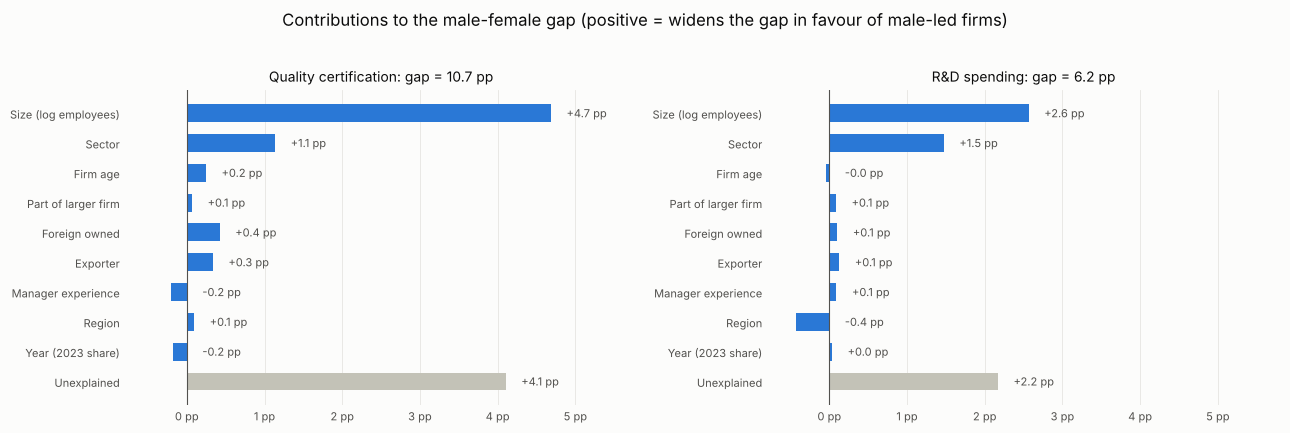

In [23]:
# Figure: what explains the quality certification and R&D gaps?
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), facecolor=SURFACE, sharex=True)
for ax, label in zip(axes, ["Quality certification", "R&D spending"]):
    ax.set_facecolor(SURFACE)
    vals = ob.loc[label, detail_cols].astype(float)[::-1]
    unexp = ob.loc[label, "Unexplained"]
    names = ["Unexplained"] + list(vals.index)
    nums = [unexp] + list(vals.values)
    colors = ["#c3c2b7"] + [BLUE] * len(vals)
    ax.barh(names, nums, color=colors, height=0.6)
    for yy, v in enumerate(nums):
        ax.text(max(v, 0) + 0.002, yy, f"{v*100:+.1f} pp", va="center", ha="left", fontsize=8, color=MUTED)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_xlim(-0.008, 0.058)
    ax.set_title(f"{label}: gap = {ob.loc[label, 'Gap (M-F)']*100:.1f} pp", fontsize=10, color=INK)
    ax.tick_params(colors=MUTED, length=0, labelsize=8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*100:.0f} pp"))
    for s in ax.spines.values(): s.set_visible(False)
    ax.grid(axis="x", color="#e6e5e1", linewidth=0.6); ax.set_axisbelow(True)
fig.suptitle("Contributions to the male-female gap (positive = widens the gap in favour of male-led firms)",
             color=INK, y=1.02)
plt.tight_layout()
fig.savefig("paper/figures/fig2_oaxaca.pdf", bbox_inches="tight", facecolor=SURFACE)
plt.show()

**Reading the figure.** Each blue bar is how much of the gap comes from female- and male-led firms differing in that characteristic. **Firm size** is by far the largest contributor. Sector adds a bit, especially for R&D. The grey bar is what remains unexplained, clearly visible for quality certification.

### Limitations of the decomposition
- It is an **accounting** exercise, not a causal one. "Explained by size" means that *if* female-led firms had the size distribution of male-led firms (and the pooled returns applied), the gap would be smaller.
- Some explanatory variables may themselves be **outcomes of gender** (barriers to credit can keep female-led firms small). Then "explained" does not mean "not related to gender". This is the classic debate about bad controls; mention it.
- We use the LPM for the decomposition. Nonlinear versions exist (Fairlie 2005), but they are beyond the course.

---
# Part 7: Checking the assumptions of every model

Every estimator above is only as good as its assumptions. This part goes through them model by model. For each assumption it says what it means, why it matters, how we check it (formal test or argument), and what we conclude. Some assumptions are testable; others (exogeneity of the key regressor, the IV exclusion restriction) can **only be argued**. Being explicit about which is which is part of a good empirical project.

| Model | Assumption | Check | Section |
|---|---|---|---|
| OLS / LPM | MLR.1 linear in parameters, correct functional form | RESET test | 7.1 |
| | MLR.2 random sampling | stratified design → sampling weights; attrition | 7.1, 8.1, 8.4 |
| | MLR.3 no perfect collinearity | VIF | 7.1 |
| | MLR.4 zero conditional mean $E(u\mid\mathbf x)=0$ | argued; proxy, IV, FE (Parts 4–5) | 7.1 |
| | MLR.5 homoskedasticity | Breusch–Pagan test | 7.1 |
| | MLR.6 normal errors | not needed (large n) | 7.1 |
| Probit / logit | correct link function $G(\cdot)$ | link test, probit vs logit | 7.2 |
| | no perfect separation | inspect cells & fitted probabilities | 7.2 |
| | good fit | pseudo-$R^2$, % correctly predicted, Hosmer–Lemeshow | 7.2 |
| | exogeneity, homoskedastic latent error | argued | 7.2 |
| IV / 2SLS | relevance | first-stage F (Part 4) | 7.3 |
| | exogeneity / exclusion | overidentification test + argument | 7.3 |
| Panel FE / FD | strict exogeneity | argued (T = 2) | 7.4 |
| | FD = FE when T = 2 | numerical check | 7.4 |
| | **parallel trends** (DiD) | **placebo test on 2010–2017** | 7.5 |
| RE | $\text{Cov}(\mathbf x_{it}, a_i)=0$ | Hausman (Part 5.4) | |
| Oaxaca–Blinder | linearity; choice of reference coefficients | sensitivity to $\boldsymbol\beta^*$ | 7.6 |

## 7.1 OLS / linear probability model: MLR.1–MLR.6

We check the assumptions on the main LPM specification (Part 2) for all five outcomes.

**MLR.1: functional form (RESET test).** If the true relation is nonlinear, adding powers of the fitted values should improve the model. Ramsey's RESET estimates

$$
y = \mathbf x'\boldsymbol\beta + \delta_1 \hat y^2 + \delta_2 \hat y^3 + \text{error}
$$

and tests $H_0: \delta_1 = \delta_2 = 0$ with an F-test. For a **binary** outcome we *expect* rejection, because the true probability must bend to stay in [0, 1]. A rejection here is an argument for probit/logit, not a reason to abandon the LPM's average effects.

**MLR.3: no perfect collinearity (VIF).** Perfect collinearity makes OLS impossible. *High* collinearity inflates standard errors. The variance inflation factor of regressor $j$ is

$$
\text{VIF}_j = \frac{1}{1 - R_j^2},
$$

where $R_j^2$ is the $R^2$ from regressing $x_j$ on all other regressors. The rule of thumb is that VIF > 10 is a concern.

**MLR.5: homoskedasticity (Breusch–Pagan).** Regress the squared residuals on the regressors, $\hat u^2 = \mathbf x'\boldsymbol\delta + \text{error}$, and test $H_0: \boldsymbol\delta = \mathbf 0$ with $LM = n R^2_{\hat u^2} \sim \chi^2_k$. For an LPM we know in advance that $\text{Var}(u\mid\mathbf x) = p(\mathbf x)[1-p(\mathbf x)]$, so the test should reject. It is reported to show that this was checked and why robust (clustered) SEs are used.

**MLR.6: normality.** The LPM error takes only two values for a given $\mathbf x$ (namely $1-p$ or $-p$), so it **cannot** be normal. This does not matter: with n ≈ 2,000, t- and F-tests are justified by the **central limit theorem** (asymptotic normality of OLS needs only MLR.1–MLR.5, and with robust SEs not even MLR.5).

**MLR.4: zero conditional mean.** This is the key assumption, $E(u \mid \text{Female}, \mathbf x) = 0$, and it **cannot be tested** directly. Parts 4 and 5 address it: the proxy changes nothing; IV is not credible; FE removes time-constant unobservables.

In [24]:
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

rows = []
for var, label in OUTCOMES.items():
    r_plain = smf.ols(f"{var} ~ {RHS}", samples[var]).fit()          # non-robust fit for the diagnostics
    bp_lm, bp_p, _, _ = het_breuschpagan(r_plain.resid, r_plain.model.exog)
    reset = linear_reset(r_plain, power=3, use_f=True)
    rows.append({"Outcome": label,
                 "RESET F": float(reset.fvalue), "RESET p": float(reset.pvalue),
                 "Breusch-Pagan LM": bp_lm, "BP p": bp_p})
reset_tbl = pd.DataFrame(rows).set_index("Outcome")
reset_tbl

,RESET F,RESET p,Breusch-Pagan LM,BP p
Outcome,,,,
New product/service,7.232,0.001,73.705,0.000
Process innovation,4.624,0.010,37.641,0.007
R&D spending,1.991,0.137,125.496,0.000
Own website,14.968,0.000,326.835,0.000
Quality certification,20.121,0.000,246.285,0.000


In [25]:
Xv = sm.add_constant(df[["female_mgr", "post", "ln_emp", "ln_age", "mgr_exp",
                         "exporter", "foreign_owned", "multi_estab"]].dropna())
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])], index=Xv.columns, name="VIF")
vif.drop("const").to_frame()

,VIF
female_mgr,1.026
post,1.135
ln_emp,1.331
ln_age,1.242
mgr_exp,1.161
exporter,1.154
foreign_owned,1.144
multi_estab,1.193


**Conclusions for OLS/LPM.**
- **RESET rejects** linearity for most outcomes, as expected for binary outcomes. This justifies reporting probit/logit, whose average effects agree with the LPM (Part 3). The LPM's *average* partial effects remain reliable even though individual predictions are not.
- **VIFs** are all close to 1, far below 10. Multicollinearity is not a problem, and the large standard errors on Female are due to the small number of female-led firms, not to collinearity.
- **Breusch–Pagan rejects** homoskedasticity strongly, as theory predicts for the LPM. All inference uses firm-clustered (heteroskedasticity-robust) standard errors, so MLR.5 is not needed.
- **Normality** is not required given the sample size.

## 7.2 Probit and logit

**1. Correct link function (Pregibon link test).** If the model is correctly specified, the linear index $\widehat{xb} = \mathbf z'\hat{\boldsymbol\beta}$ should be enough to predict $y$, and its square should add nothing. Re-estimate

$$
P(y=1) = G(\gamma_0 + \gamma_1 \widehat{xb} + \gamma_2 \widehat{xb}^2)
$$

and test $H_0: \gamma_2 = 0$. Rejection signals an omitted variable or the wrong link.

**2. Goodness of fit.**
- **McFadden pseudo-$R^2$** $= 1 - \ell_{UR}/\ell_0$, where $\ell_0$ is the log-likelihood with only a constant.
- **Percent correctly predicted:** predict $\tilde y = 1$ if $\hat P \ge 0.5$. It is reported *separately* for $y = 0$ and $y = 1$, because with an unbalanced outcome a model can look good by always predicting the majority class.
- **Hosmer–Lemeshow test:** sort firms into 10 groups by predicted probability and compare observed with expected counts:

$$
HL = \sum_{g=1}^{10} \frac{(O_g - E_g)^2}{E_g\,(1 - E_g/n_g)} \;\sim\; \chi^2_8
$$

A large p-value means the predicted probabilities are consistent with the observed frequencies.

**3. No perfect separation.** If some regressor value (a sector, say) perfectly predicts $y=0$ or $y=1$, the MLE does not exist (a coefficient goes to ±∞). We check the smallest cell count of each outcome within each sector and region.

**4. Assumptions that can only be argued.** As in OLS, $e$ must be independent of the regressors (exogeneity). Additionally, the latent error must be **homoskedastic**: in probit, heteroskedasticity makes the estimator *inconsistent*, not just inefficient, because the scale of $e$ is normalised to 1. We can't test this cleanly with the course tools. The close agreement of LPM, probit and logit APEs is reassuring, because three different functional assumptions give the same answer.

In [26]:
def hosmer_lemeshow(y, p, groups=10):
    d = pd.DataFrame({"y": y, "p": p})
    d["g"] = pd.qcut(d["p"].rank(method="first"), groups, labels=False)
    agg = d.groupby("g").agg(O=("y", "sum"), E=("p", "sum"), n=("y", "size"))
    hl = (((agg.O - agg.E) ** 2) / (agg.E * (1 - agg.E / agg.n))).sum()
    return hl, 1 - stats.chi2.cdf(hl, groups - 2)

rows = []
for var, label in OUTCOMES.items():
    d = samples[var].copy()
    for model_name, fn in [("Probit", smf.probit), ("Logit", smf.logit)]:
        res = fn(f"{var} ~ {RHS}", d).fit(disp=0)
        d["xb"] = res.fittedvalues            # linear index z'b
        d["xb2"] = d["xb"] ** 2
        link = fn(f"{var} ~ xb + xb2", d).fit(disp=0)
        p_hat = res.predict(d)
        pred = (p_hat >= 0.5).astype(int)
        y = d[var]
        hl, hl_p = hosmer_lemeshow(y, p_hat)
        rows.append({"Outcome": label, "Model": model_name,
                     "Log-lik": res.llf, "Pseudo R2": res.prsquared,
                     "Link test p (xb^2)": link.pvalues["xb2"],
                     "% correct y=1": 100 * (pred[y == 1] == 1).mean(),
                     "% correct y=0": 100 * (pred[y == 0] == 0).mean(),
                     "Hosmer-Lemeshow p": hl_p})
probitdiag_tbl = pd.DataFrame(rows).set_index(["Outcome", "Model"])
probitdiag_tbl

Log-lik  Pseudo R2  Link test p (xb^2)  % correct y=1  % correct y=0  Hosmer-Lemeshow p
Outcome               Model                                                                                            
New product/service   Probit -1,186.756      0.053               0.081         93.369         22.054              0.162
                      Logit  -1,186.516      0.053               0.084         93.292         22.205              0.239
Process innovation    Probit -1,262.262      0.052               0.010         81.244         39.452              0.475
                      Logit  -1,262.080      0.052               0.010         81.335         39.333              0.499
R&D spending          Probit -1,005.033      0.081               0.980         13.017         97.005              0.777
                      Logit  -1,005.062      0.081               0.830         13.843         96.937              0.419
Own website           Probit   -959.024      0.158               0.971         92.608         27.238              0.812
                      Logit    -959.459      0.157               0.521         92.329         28.000              0.787
Quality certification Probit   -709.465      0.270               0.992         39.642         95.179              0.157
                      Logit    -710.733      0.269               0.490         40.153         94.984              0.395

In [27]:
# Perfect separation check: smallest number of 0s or 1s in any sector or region cell
rows = []
for var, label in OUTCOMES.items():
    d = samples[var]
    sec = pd.crosstab(d["sector"], d[var]).min().min()
    reg = pd.crosstab(d["region"], d[var]).min().min()
    rows.append({"Outcome": label, "Smallest sector cell": sec, "Smallest region cell": reg})
sep_tbl = pd.DataFrame(rows).set_index("Outcome")
sep_tbl

,Smallest sector cell,Smallest region cell
Outcome,,
New product/service,31,48
Process innovation,41,65
R&D spending,20,32
Own website,15,52
Quality certification,8,11


**Conclusions for probit/logit.**
- **Link test:** the squared index is insignificant for R&D, website and quality certification, borderline for new products (p ≈ 0.08), and **significant for process innovation (p ≈ 0.01)**. For process innovation the specification may be missing something, such as a nonlinearity in size or an interaction. Report it honestly. Since process innovation shows no significant gender effect in any model, it does not change the conclusions.
- **Probit vs logit:** log-likelihoods are almost identical, so the data cannot distinguish the normal from the logistic distribution. That is typical, and it is why both give the same APEs.
- **Prediction:** the models predict the majority class well and the minority class poorly (e.g. only about 40% of certified firms are predicted as certified, and about 13% of R&D spenders). This is normal for weak predictors and does not invalidate the APEs. The goal is to estimate effects, not to forecast.
- **Hosmer–Lemeshow:** all p-values are above 0.15, so the predicted probabilities are well calibrated against observed frequencies for every outcome.
- **Separation:** every sector and region cell contains both 0s and 1s (smallest cell: 8 certified firms in one sector), so the MLE exists.

## 7.3 IV: relevance and exogeneity

- **Relevance** was confirmed in Part 4 (first-stage F ≈ 270–280 ≫ 10).
- **Exogeneity** is untestable with *one* instrument (exactly identified). With **two** instruments we can run an **overidentification test**: if both instruments are valid, they should give the same 2SLS estimate up to sampling error. We use *any* female owner and *majority* female ownership. Since the clustered covariance is used, the robust version (Wooldridge's score test) is reported:

$$
H_0: \text{all instruments are exogenous}, \qquad \text{test statistic} \sim \chi^2_{(\#\text{instruments} - \#\text{endogenous})} = \chi^2_1
$$

**Important limitation.** The test only checks whether the instruments *agree with each other*. Both come from the same source (owner gender), so if both are invalid in the same direction the test will not reject. A non-rejection is weak evidence, and the exclusion restriction still has to be argued, and here we argue it is doubtful.

In [28]:
rows = []
for var, label in OUTCOMES.items():
    d = df[[var, "female_mgr", "mgr_exp", "female_own_any", "female_own_major", "post", "ln_emp", "ln_age",
            "exporter", "foreign_owned", "multi_estab", "sector", "region", "panelid"]].dropna().reset_index(drop=True)
    iv2 = IV2SLS.from_formula(
        f"{var} ~ 1 + post + ln_emp + ln_age + mgr_exp + exporter + foreign_owned + multi_estab"
        f" + C(sector) + C(region) + [female_mgr ~ female_own_any + female_own_major]", d
    ).fit(cov_type="clustered", clusters=d["panelid"])
    oid = iv2.wooldridge_overid
    rows.append({"Outcome": label, "2SLS (2 instruments)": f"{iv2.params.female_mgr:.3f} ({iv2.std_errors.female_mgr:.3f})",
                 "First-stage F": float(iv2.first_stage.diagnostics.loc['female_mgr', 'f.stat']),
                 "Overid. stat": oid.stat, "Overid. p": oid.pval})
overid_tbl = pd.DataFrame(rows).set_index("Outcome")
overid_tbl

,2SLS (2 instruments),First-stage F,Overid. stat,Overid. p
Outcome,,,,
New product/service,0.047 (0.051),494.617,0.284,0.594
Process innovation,0.018 (0.051),497.694,0.306,0.580
R&D spending,-0.030 (0.042),497.711,0.015,0.902
Own website,-0.013 (0.047),499.224,0.647,0.421
Quality certification,-0.047 (0.035),472.827,0.488,0.485


**Conclusion for IV.** The instruments are strong (first-stage F ≈ 470–500 with two instruments), and the overidentification test does not reject, but for the reason above this does **not** validate them. The paper should present IV as a check that was considered and rejected on economic grounds, which is better than omitting it or over-selling it.

## 7.4 Panel fixed effects / first differences

**Strict exogeneity:** $E(u_{it} \mid \mathbf x_{i,2017}, \mathbf x_{i,2023}, a_i) = 0$. The error in *either* period must be unrelated to the regressors in *both* periods. It fails if there is **feedback**: a shock to website adoption in 2017 that changes who manages the firm in 2023. With T > 2 this can be tested by adding future regressors ($x_{i,t+1}$); with T = 2 it cannot. We argue it is plausible for the DiD specification, because the treatment indicator (female-led *in 2017*) is fixed **before** the 2017–2023 shocks occur.

**Serial correlation.** With T = 2, first differencing leaves one observation per firm, so serial correlation in $\Delta u_i$ is not an issue. Clustering by firm in the FE estimator handles it anyway.

**Heteroskedasticity** is handled by firm-clustered SEs.

**FD = FE when T = 2.** The numbers below confirm this: estimating the website DiD by OLS on the first-differenced data gives exactly the FE coefficient. This is a good check that the panel is set up correctly.

In [29]:
var = "website"
cols = [var, "post", "female_2017", "ln_emp", "mgr_exp", "exporter", "foreign_owned", "multi_estab"]
w = pan[["panelid", "year"] + cols].dropna()
w = w[w.groupby("panelid")["year"].transform("count") == 2].sort_values(["panelid", "year"])
diff = w.groupby("panelid")[[var, "ln_emp", "mgr_exp", "exporter", "foreign_owned", "multi_estab"]].diff().dropna()
diff["female_2017"] = w.groupby("panelid")["female_2017"].first().reindex(w.loc[diff.index, "panelid"]).values
fd = smf.ols(f"{var} ~ female_2017 + ln_emp + mgr_exp + exporter + foreign_owned + multi_estab", diff).fit(cov_type="HC1")
print(f"First differences (OLS on Δ-data): Female2017 = {fd.params['female_2017']:.4f}  (SE {fd.bse['female_2017']:.4f}),  N = {int(fd.nobs)} firms")
print(f"Fixed effects (Table 4):           Female2017xPost = {fe_store['website'].params['f17_post']:.4f}  (SE {fe_store['website'].std_errors['f17_post']:.4f})")
print(f"FD intercept = change for male-led firms = {fd.params['Intercept']:.4f};  FE coefficient on Post = {fe_store['website'].params['post']:.4f}")

First differences (OLS on Δ-data): Female2017 = 0.1265  (SE 0.0631),  N = 350 firms
Fixed effects (Table 4):           Female2017xPost = 0.1265  (SE 0.0628)
FD intercept = change for male-led firms = 0.0605;  FE coefficient on Post = 0.0605


## 7.5 Parallel trends: a placebo test on the pre-COVID period (2010 → 2017)

The DiD in Part 5 interprets the extra catch-up of female-led firms as related to the COVID period. That requires **parallel trends**: without COVID, female- and male-led firms would have changed by the same amount. With only 2017 and 2023 this can't be tested, **but** the earlier Enterprise Surveys panel (2006–2010–2017) gives a pre-period.

**Placebo test.** Run the *same* FE DiD on firms observed in 2010 and 2017, a period with no pandemic:

$$
y_{it} = \delta\,\text{Post}_{2017} + \beta_3^{\text{placebo}}\,(\text{Female}_{i,2010} \times \text{Post}_{2017}) + \mathbf x_{it}'\boldsymbol\gamma + a_i + u_{it}
$$

- If $\hat\beta_3^{\text{placebo}} \approx 0$: female-led firms were **not** already catching up before COVID. That supports parallel trends and makes the 2017–2023 result more credible as a COVID-period effect.
- If it is clearly positive: the 2017–2023 catch-up may just continue a pre-existing trend.

(Caveat: the 2010 questionnaire differed somewhat. The panel file harmonises the variables, but the innovation questions are less comparable than website and certification.)

In [30]:
old = pd.read_stata("Peru_2006_2010_2017.dta", convert_categoricals=False)
old = old[old["year"].isin([2010, 2017])].copy()
yn = lambda s: s.map({1: 1, 2: 0}).astype(float)
old["female_mgr"] = yn(old["_2010_2017_b7a"])
for v, src in [("website", "c22b"), ("new_product", "h1"), ("process_innov", "h5"), ("rd", "h8"), ("quality_cert", "b8")]:
    old[v] = yn(old[src])
l1_old = old["l1"].astype(float).where(old["l1"] > 0)
old["ln_emp"] = np.log(l1_old)
old["exporter"] = (old["d3c"] >= 10).astype(float)
old["foreign_owned"] = (old["b2b"] >= 10).astype(float).where(old["b2b"] >= 0)
old["multi_estab"] = yn(old["a7"])
old["mgr_exp"] = old["b7"].astype(float).where(old["b7"] >= 0)
old["post"] = (old["year"] == 2017).astype(int)
both = old.groupby("panelid")["year"].nunique()
old = old[old["panelid"].isin(both[both == 2].index)]
f10 = old.loc[old.year == 2010].set_index("panelid")["female_mgr"].rename("female_2010")
old = old.join(f10, on="panelid")
old["f10_post"] = old["female_2010"] * old["post"]
OP = old.set_index(["panelid", "year"])
print(f"Firms observed in both 2010 and 2017: {old.panelid.nunique()}  (female-led in 2010: {f10.mean():.1%})")

rows = []
for var, label in OUTCOMES.items():
    d = OP[[var, "post", "f10_post", "ln_emp", "mgr_exp", "exporter", "foreign_owned", "multi_estab"]].dropna()
    r = PanelOLS.from_formula(f"{var} ~ post + f10_post + {PCTRL} + EntityEffects", d).fit(cov_type="clustered", cluster_entity=True)
    main = fe_store[var]
    rows.append({"Outcome": label,
                 "Placebo 2010→2017": f"{r.params.f10_post:.3f}{stars(r.pvalues.f10_post)} ({r.std_errors.f10_post:.3f})",
                 "Main 2017→2023": f"{main.params.f17_post:.3f}{stars(main.pvalues.f17_post)} ({main.std_errors.f17_post:.3f})",
                 "Placebo N firms": int(r.entity_info.total)})
print("FE DiD, Female(base year) x Post. Firm-clustered SEs.")
placebo_tbl = pd.DataFrame(rows).set_index("Outcome")
placebo_tbl

Firms observed in both 2010 and 2017: 374  (female-led in 2010: 11.2%)


FE DiD, Female(base year) x Post. Firm-clustered SEs.


,Placebo 2010→2017,Main 2017→2023,Placebo N firms
Outcome,,,
New product/service,-0.057 (0.119),-0.044 (0.077),370
Process innovation,-0.126 (0.131),0.024 (0.083),369
R&D spending,-0.148 (0.119),-0.060 (0.060),370
Own website,0.046 (0.066),0.127** (0.063),374
Quality certification,0.106 (0.078),0.018 (0.050),373


**Conclusion.** For **website**, the placebo estimate is small and insignificant: female-led firms were not catching up between 2010 and 2017. This supports the parallel-trends assumption and the reading that the 2017–2023 catch-up is specific to the COVID period. Two caveats belong in the paper: the placebo SE is about as large as the main SE, so the test is not very powerful, and only about 11% of the 2010 panel firms are female-led.

## 7.6 Oaxaca–Blinder: sensitivity to the reference coefficients

The decomposition assumes a linear model in each group (fine for averages, as with the LPM) and requires a choice of $\boldsymbol\beta^*$ (the **index number problem**). We re-run it with the male coefficients ($\boldsymbol\beta^* = \hat{\boldsymbol\beta}_M$: "what if female-led firms had male-led characteristics, valued at male-led returns?") and with the female coefficients. If the explained share is similar across references, the conclusion of Part 6 is robust.

In [31]:
def oaxaca_ref(d, var, ref):
    X = build_X(d); y = d[var].values.astype(float)
    m, f = (d.female_mgr == 0).values, (d.female_mgr == 1).values
    bM, bF = ols_beta(X.values[m], y[m]), ols_beta(X.values[f], y[f])
    bP = ols_beta(np.column_stack([X.values, d.female_mgr.values]), y)[:-1]
    b_star = {"pooled": bP, "male": bM, "female": bF}[ref]
    xM, xF = X.values[m].mean(0), X.values[f].mean(0)
    gap = y[m].mean() - y[f].mean()
    return 100 * ((xM - xF) @ b_star) / gap

rows = []
for var, label in OUTCOMES.items():
    if var == "process_innov":
        continue   # raw gap ~0, percentages meaningless (see Part 6)
    d = df[[var, "female_mgr", "sector", "region", "panelid"] + OB_VARS].dropna().reset_index(drop=True)
    rows.append({"Outcome": label, **{f"% explained, b* = {r}": oaxaca_ref(d, var, r) for r in ["pooled", "male", "female"]}})
obsens_tbl = pd.DataFrame(rows).set_index("Outcome")
obsens_tbl

,"% explained, b* = pooled","% explained, b* = male","% explained, b* = female"
Outcome,,,
New product/service,35.511,33.365,33.568
R&D spending,64.960,65.266,66.349
Own website,71.428,68.071,92.752
Quality certification,61.714,61.969,60.651


**Conclusion.** Read across each row. If the explained share stays in the same range whichever coefficients are used, H3 is robust to the index-number choice. Where the female-coefficient version differs a lot, that is because it relies on a regression estimated on only about 400 firms, so its coefficients are noisy. That is the reason the pooled reference is preferred.

### Chow test: do male- and female-led firms follow the same regression function?

The pooled reference $\boldsymbol\beta^*$ is appropriate when the two groups share the same slopes (Decompositions lecture, slides 13–16 and 21–22). The Chow test interacts every regressor (and the intercept) with Female and tests that all interactions are zero. The classical Chow $F$ requires homoskedasticity, which the LPM violates, so we use the robust Wald version with firm-clustered standard errors.

In [32]:
rows = []
for var, label in OUTCOMES.items():
    d = df[[var, "female_mgr", "sector", "region", "panelid"] + OB_VARS].dropna().reset_index(drop=True)
    base = " + ".join(OB_VARS) + " + C(sector) + C(region)"
    r = smf.ols(f"{var} ~ ({base}) * female_mgr", d).fit(cov_type="cluster", cov_kwds={"groups": d["panelid"]})
    inter = [n for n in r.params.index if "female_mgr" in n]
    R = np.zeros((len(inter), len(r.params)))
    for k, n in enumerate(inter):
        R[k, list(r.params.index).index(n)] = 1
    w = r.wald_test(R, scalar=True)
    rows.append({"Outcome": label, "Restrictions": len(inter), "Robust Chow stat": float(w.statistic), "p-value": float(w.pvalue)})
chow_tbl = pd.DataFrame(rows).set_index("Outcome")
chow_tbl

,Restrictions,Robust Chow stat,p-value
Outcome,,,
New product/service,18,15.119,0.654
Process innovation,18,34.975,0.010
R&D spending,18,14.752,0.679
Own website,18,14.548,0.693
Quality certification,18,19.061,0.388


---
# Part 8: Robustness checks and remaining results

## 8.1 Sampling weights

The Enterprise Surveys use **stratified random sampling** (by size, sector and region), with large firms over-sampled. Unweighted estimates describe the *sample*; weighted estimates describe the *population* of Peruvian formal firms. In regression the textbook view is:
- If the model is correctly specified and the strata variables are controlled for (size, sector and region are in $\mathbf x$), weighting is not needed for consistency, and the unweighted estimator is more efficient.
- If weighted and unweighted estimates **differ a lot**, that signals heterogeneous effects or misspecification and is worth reporting.

Weighted least squares minimises $\sum_i w_i (y_i - \mathbf x_i'\boldsymbol\beta)^2$ with $w_i$ = sampling weight (`wmedian`).

In [33]:
rows = []
for var, label in OUTCOMES.items():
    d = df[[var, "weight"] + BASE_COLS].dropna().reset_index(drop=True)
    u = smf.ols(f"{var} ~ {RHS}", d).fit(cov_type="cluster", cov_kwds={"groups": d["panelid"]})
    w = smf.wls(f"{var} ~ {RHS}", d, weights=d["weight"]).fit(cov_type="cluster", cov_kwds={"groups": d["panelid"]})
    c = lambda r, t: f"{r.params[t]:.3f}{stars(r.pvalues[t])} ({r.bse[t]:.3f})"
    rows.append({"Outcome": label, "Female, unweighted": c(u, "female_mgr"), "Female, weighted": c(w, "female_mgr"),
                 "FxPost, unweighted": c(u, "female_mgr_x_post"), "FxPost, weighted": c(w, "female_mgr_x_post")})
weights_tbl = pd.DataFrame(rows).set_index("Outcome")
weights_tbl

,"Female, unweighted","Female, weighted","FxPost, unweighted","FxPost, weighted"
Outcome,,,,
New product/service,-0.018 (0.038),-0.154** (0.077),-0.036 (0.052),0.162 (0.131)
Process innovation,-0.010 (0.040),-0.055 (0.079),0.053 (0.053),0.164 (0.135)
R&D spending,-0.031 (0.033),-0.074 (0.050),0.018 (0.044),0.088 (0.118)
Own website,-0.030 (0.037),-0.001 (0.059),0.023 (0.046),-0.024 (0.090)
Quality certification,-0.032 (0.024),-0.089** (0.042),-0.017 (0.034),0.070 (0.052)


**Reading the table.** Weighted standard errors are about twice as large, because weights are very unequal (see Kish's effective sample size in Part 1). Two estimates change:
- **Quality certification:** the 2017 gap becomes larger (about −9 pp) and significant at 5%.
- **New products:** the 2017 gap becomes about −15 pp and significant at 5%, although it was insignificant unweighted.

**How to interpret this.** Weighted and unweighted OLS estimate **different averages** when effects differ across firms. Unweighted OLS gives more weight to the over-sampled (large) firms and to strata where Female varies more; weighted OLS targets the population average. Controlling for the strata does **not** make the two equivalent if the gender gap is heterogeneous. The difference between them is therefore informative: it signals **heterogeneity** in the gender gap across strata. Part 8.5 tests the most obvious source, firm size, directly. Neither estimate is "the right one": the unweighted estimate is more precise, the weighted one more representative but noisy.

## 8.2 Female ownership instead of female top manager

The two papers used in the introduction measure gender through **ownership**, not management (Wagner 2022: any female owner; Hyland et al. 2021: majority female ownership). To compare with them, we replace `female_mgr` with **majority female ownership** (> 50% owned by women):

$$
y_{it} = \beta_0 + \beta_1\,\text{FemOwn}_{it} + \beta_2\,\text{Post}_t + \beta_3\,(\text{FemOwn}_{it}\times\text{Post}_t) + \mathbf x_{it}'\boldsymbol\gamma + u_{it}
$$

In [34]:
df["fo_post"] = df["female_own_major"] * df["post"]
RHS_OWN = "female_own_major + post + fo_post + " + CONTROLS
rows = []
for var, label in OUTCOMES.items():
    d = df[[var, "female_own_major", "fo_post"] + BASE_COLS].dropna().reset_index(drop=True)
    r = smf.ols(f"{var} ~ {RHS_OWN}", d).fit(cov_type="cluster", cov_kwds={"groups": d["panelid"]})
    c = lambda t: f"{r.params[t]:.3f}{stars(r.pvalues[t])} ({r.bse[t]:.3f})"
    rows.append({"Outcome": label, "Majority female-owned (2017 gap)": c("female_own_major"),
                 "FemOwn x Post": c("fo_post"), "N": int(r.nobs)})
print(f"Share of majority female-owned firms: {df.female_own_major.mean():.1%};  overlap with female manager: "
      f"{df.loc[df.female_own_major==1,'female_mgr'].mean():.1%} of them have a female top manager")
own_tbl = pd.DataFrame(rows).set_index("Outcome")
own_tbl

Share of majority female-owned firms: 21.1%;  overlap with female manager: 63.3% of them have a female top manager


,Majority female-owned (2017 gap),FemOwn x Post,N
Outcome,,,
New product/service,0.034 (0.037),-0.010 (0.051),1910
Process innovation,0.024 (0.040),-0.035 (0.055),1900
R&D spending,-0.032 (0.031),0.029 (0.043),1906
Own website,-0.004 (0.037),0.004 (0.044),1910
Quality certification,-0.026 (0.024),0.009 (0.032),1879


**Reading the table.** With ownership as the gender measure, no gap or change is significant. Results are qualitatively the same as with the manager definition. The paper can say the null results for innovation are not an artefact of the gender definition.

## 8.3 Multiple testing

We test five outcomes. Even if manager gender had **no** effect on any of them, the chance that at least one of five independent tests is significant at 5% is $1 - 0.95^5 \approx 23\%$. The **Holm–Bonferroni** correction controls the *family-wise error rate* (the probability of at least one false positive):
1. Sort the p-values from smallest to largest: $p_{(1)} \le \dots \le p_{(5)}$.
2. Compare $p_{(k)}$ with $\alpha / (5 - k + 1)$, so the smallest p-value must be below $0.05/5 = 0.01$.
3. Stop at the first non-rejection.

The adjusted p-value of the smallest test is $5 \times p_{(1)}$.

In [35]:
from statsmodels.stats.multitest import multipletests
labels = list(OUTCOMES.values())
p_fe = [fe_store[v].pvalues["f17_post"] for v in OUTCOMES]
p_pool = [lpm_res[v].pvalues["female_mgr_x_post"] for v in OUTCOMES]
p_gap = [lpm_res[v].pvalues["female_mgr"] for v in OUTCOMES]
holm_tbl = pd.DataFrame({
    "FE DiD p": p_fe, "FE DiD p (Holm)": multipletests(p_fe, method="holm")[1],
    "Pooled DiD p": p_pool, "Pooled DiD p (Holm)": multipletests(p_pool, method="holm")[1],
    "2017 gap p": p_gap, "2017 gap p (Holm)": multipletests(p_gap, method="holm")[1],
}, index=labels)
holm_tbl

,FE DiD p,FE DiD p (Holm),Pooled DiD p,Pooled DiD p (Holm),2017 gap p,2017 gap p (Holm)
New product/service,0.566,1.000,0.486,1.000,0.628,1.000
Process innovation,0.774,1.000,0.322,1.000,0.798,1.000
R&D spending,0.323,1.000,0.676,1.000,0.334,1.000
Own website,0.045,0.223,0.615,1.000,0.418,1.000
Quality certification,0.718,1.000,0.618,1.000,0.180,0.901


**Conclusion.** After the Holm correction, the website DiD (raw p ≈ 0.045) is **no longer significant** (adjusted p ≈ 0.22). The paper should be transparent: the website catch-up is the **only** effect that comes close to significance, it is supported by the raw data and passes the placebo test, but it does not survive a strict correction for testing five outcomes. Call it *suggestive*, not conclusive. Reporting this honestly is exactly what the project guidelines ask for ("avoid this temptation to misrepresent your results").

## 8.4 Survival and panel attrition: which 2017 firms disappeared by 2023?

Our 2023 data only include firms that **survived**. If female- and male-led firms exited at different rates during COVID, the 2023 sample is **selected**, and the DiD compares survivors with survivors. This is a violation of random sampling (MLR.2), a form of **sample selection**.

The 2023 panel file records what happened to every 2017 firm (`eligibility2023`): re-interviewed, confirmed **closed** ("discontinued business"), refused, or not reachable. We estimate two LPMs on the 2017 cross-section:

$$
\text{Closed}_i = \alpha_0 + \alpha_1\,\text{Female}_{i,2017} + \mathbf x_{i,2017}'\boldsymbol\gamma + e_i,
\qquad
\text{Reinterviewed}_i = \dots
$$

This is also the outcome studied by **Wagner (2022)**, who finds that firms with a female owner were *less* likely to exit during COVID in 10 European countries, and by **Hyland et al. (2021)**, who find equal permanent-closure rates but more temporary closures for female-owned firms.

In [36]:
raw23 = pd.read_stata("Peru_2017_2023.dta", convert_categoricals=False)
status = raw23.loc[raw23.year == 2017, ["panelid", "eligibility2023", "panel"]]
d17 = df[df.year == 2017].merge(status, on="panelid")
d17["reinterviewed"] = (d17["panel"] == 3).astype(int)
d17["closed"] = d17["eligibility2023"].str.startswith(("616", "618", "619", "620", "621")).astype(int)

print("Share of 2017 firms, by manager gender in 2017:")
print(d17.groupby("female_mgr")[["reinterviewed", "closed"]].mean().rename(index={0: "Male-led", 1: "Female-led"}))

ctrl17 = "ln_emp + ln_age + mgr_exp + exporter + foreign_owned + multi_estab + C(sector) + C(region)"
rows = []
for y in ["closed", "reinterviewed"]:
    d = d17[[y, "female_mgr", "ln_emp", "ln_age", "mgr_exp", "exporter", "foreign_owned", "multi_estab", "sector", "region"]].dropna()
    lpm = smf.ols(f"{y} ~ female_mgr + {ctrl17}", d).fit(cov_type="HC1")
    prb = smf.probit(f"{y} ~ female_mgr + {ctrl17}", d).fit(disp=0)
    ape = prb.get_margeff(at="overall", dummy=True).summary_frame().loc["female_mgr"]
    rows.append({"Outcome": y, "LPM: Female": f"{lpm.params.female_mgr:.3f}{stars(lpm.pvalues.female_mgr)} ({lpm.bse.female_mgr:.3f})",
                 "Probit APE: Female": f"{ape['dy/dx']:.3f}{stars(ape['Pr(>|z|)'])} ({ape['Std. Err.']:.3f})",
                 "Mean of outcome": d[y].mean(), "N": len(d)})
surv_tbl = pd.DataFrame(rows).set_index("Outcome")
surv_tbl

Share of 2017 firms, by manager gender in 2017:
            reinterviewed  closed
female_mgr                       
Male-led            0.349   0.083
Female-led          0.390   0.064


,LPM: Female,Probit APE: Female,Mean of outcome,N
Outcome,,,,
closed,-0.036* (0.021),-0.037* (0.019),0.081,986
reinterviewed,0.056 (0.040),0.054 (0.041),0.357,986


**Reading the results.**
- Female-led firms in 2017 were about **3–4 pp less likely to be confirmed closed** by 2023 (significant at 10%), relative to an average closure rate of about 8%. This is the **same direction and similar magnitude as Wagner (2022)** (−0.9 pp on a 4.6% exit rate). It is a nice external-validity link for the introduction or discussion.
- Female-led firms were *not* significantly less likely to be re-interviewed.

**What this means for the DiD.** If the male-led firms that closed were the *weaker* ones, the surviving male-led firms in 2023 are positively selected, which makes male-led firms look better in 2023 than they would without exits. That would bias the DiD **against** finding a female catch-up. The website catch-up is therefore, if anything, **understated** by survivorship. This argument should be made in the discussion section.

## 8.5 Heterogeneity by firm size: testing it instead of inferring it

The weighted results suggest the gender gap differs across strata. Rather than *guessing* that the gaps are "concentrated among small firms", we **test** it by interacting Female with a small-firm dummy (5–19 employees, the survey's size stratum):

$$
y_{it} = \beta_0 + \beta_1 F_{it} + \beta_2\, \text{Small}_{it} + \beta_4\,(F_{it} \times \text{Small}_{it}) + \beta_5\,\text{Post}_t + \beta_3\,(F_{it}\times\text{Post}_t) + \mathbf x_{it}'\boldsymbol\gamma + u_{it}
$$

- $\beta_1$ = female gap among **medium and large** firms
- $\beta_1 + \beta_4$ = female gap among **small** firms (tested with a t-test on the linear combination)
- $\beta_4$ = **difference** between the two; $H_0: \beta_4 = 0$ means the gap does not depend on size

Log employees stays in $\mathbf x$, so Small captures a discrete difference beyond the smooth size effect.

In [37]:
df["small"] = (df["size"] == "small").astype(int)
print(f"Share of small firms: male-led {df.loc[df.female_mgr==0,'small'].mean():.1%}, female-led {df.loc[df.female_mgr==1,'small'].mean():.1%}")
rows = []
for var, label in OUTCOMES.items():
    d = df[[var, "small"] + BASE_COLS].dropna().reset_index(drop=True)
    r = smf.ols(f"{var} ~ female_mgr * small + post + female_mgr_x_post + {CONTROLS}", d).fit(
        cov_type="cluster", cov_kwds={"groups": d["panelid"]})
    g = r.t_test("female_mgr + female_mgr:small = 0")
    c = lambda e, s, p: f"{e:.3f}{stars(p)} ({s:.3f})"
    rows.append({"Outcome": label,
                 "Female: medium/large": c(r.params.female_mgr, r.bse.female_mgr, r.pvalues.female_mgr),
                 "Female: small": c(float(g.effect[0]), float(g.sd[0][0]), float(g.pvalue)),
                 "Difference (F x Small)": c(r.params["female_mgr:small"], r.bse["female_mgr:small"], r.pvalues["female_mgr:small"])})
size_tbl = pd.DataFrame(rows).set_index("Outcome")
size_tbl

Share of small firms: male-led 43.5%, female-led 61.2%


,Female: medium/large,Female: small,Difference (F x Small)
Outcome,,,
New product/service,-0.005 (0.052),-0.035 (0.043),-0.030 (0.055)
Process innovation,0.040 (0.054),-0.037 (0.045),-0.077 (0.056)
R&D spending,-0.063 (0.048),-0.016 (0.034),0.047 (0.047)
Own website,0.038 (0.043),-0.062 (0.043),-0.100** (0.047)
Quality certification,-0.085** (0.038),-0.005 (0.024),0.080** (0.037)


**Reading the table.** The heterogeneity is real but **goes in different directions** for different outcomes:
- **Quality certification:** the gap is concentrated among **medium and large** firms (about −8.5 pp, significant), and is essentially zero among small firms; the difference is significant. Certification matters mainly for larger firms that sell to demanding clients or export, and that is where female-led firms lag.
- **Website:** the opposite. The gap is larger among **small** firms, and the interaction is significant.
- **New products, process innovation, R&D:** no significant heterogeneity.

So the simple story "gaps are concentrated among small firms" is **not** supported. The weighted–unweighted differences reflect heterogeneity, but not one size gradient. The paper should report the test and drop the speculative claim. This is a good example of why a hypothesis suggested by the data should be tested rather than asserted.

## 8.6 Sensitivity of the panel DiD to the control variables

Two concerns about the controls in the FE DiD (Part 5.3):

1. **Bad controls (post-treatment variables).** Employment, exporting and foreign ownership in 2023 may themselves have been affected by the pandemic, possibly differently for female-led firms. If the pathway is *female-led → pandemic response → employment 2023 → website*, controlling for 2023 employment removes part of the effect. **Check:** drop the time-varying controls.

2. **Convergence from a lower starting point.** Female-led firms differ in baseline characteristics (smaller, less often exporters). If firms with these characteristics were catching up anyway between 2017 and 2023, the DiD attributes this to gender. **Check:** allow firms with different **2017** characteristics to follow different trends by adding $\mathbf x_{i,2017} \times \text{Post}_t$. These are **predetermined**, so they cannot be affected by the pandemic:

$$
y_{it} = \delta\,\text{Post}_t + \beta_3\,(F_{i,2017}\times\text{Post}_t) + (\mathbf x_{i,2017}\times\text{Post}_t)'\boldsymbol\lambda + a_i + \varepsilon_{it}
$$

If $\hat\beta_3$ is stable across the three specifications, the result is robust; if it shrinks with baseline controls × Post, part of the "female catch-up" is general convergence of firms that started behind.

In [38]:
BASE_VARS = ["ln_emp", "exporter", "foreign_owned", "multi_estab", "mgr_exp"]
base17 = pan.loc[pan.year == 2017].set_index("panelid")[BASE_VARS]
for v in BASE_VARS:
    pan[f"{v}_17xpost"] = pan["panelid"].map(base17[v]) * pan["post"]
P = pan.set_index(["panelid", "year"])

SPECS = {
    "No controls": [],
    "Current controls": ["ln_emp", "mgr_exp", "exporter", "foreign_owned", "multi_estab"],
    "2017 controls x Post": [f"{v}_17xpost" for v in BASE_VARS],
}
rows, did_sens_raw = [], {}
for var, label in OUTCOMES.items():
    row = {"Outcome": label}
    for name, ctrls in SPECS.items():
        d = P[[var, "post", "f17_post"] + ctrls].dropna()
        d = d[d.groupby(level=0)[var].transform("size") == 2]          # keep firms observed in both waves
        rhs = " + ".join(["post", "f17_post"] + ctrls)
        r = PanelOLS.from_formula(f"{var} ~ {rhs} + EntityEffects", d).fit(cov_type="clustered", cluster_entity=True)
        row[name] = f"{r.params.f17_post:.3f}{stars(r.pvalues.f17_post)} ({r.std_errors.f17_post:.3f})"
        did_sens_raw[(label, name)] = (r.params.f17_post, r.std_errors.f17_post, r.pvalues.f17_post, int(r.entity_info.total))
    rows.append(row)
did_sens_tbl = pd.DataFrame(rows).set_index("Outcome")
print("FE DiD coefficient on Female2017 x Post under three control sets. Firm-clustered SEs.")
did_sens_tbl

FE DiD coefficient on Female2017 x Post under three control sets. Firm-clustered SEs.


,No controls,Current controls,2017 controls x Post
Outcome,,,
New product/service,-0.041 (0.077),-0.044 (0.077),-0.058 (0.077)
Process innovation,0.024 (0.083),0.024 (0.083),0.031 (0.084)
R&D spending,-0.065 (0.060),-0.060 (0.060),-0.084 (0.060)
Own website,0.118* (0.063),0.127** (0.063),0.087 (0.060)
Quality certification,0.011 (0.051),0.018 (0.050),0.014 (0.051)


**Reading the table (focus on website).**
- **No controls vs. current controls:** the estimate barely changes (about 0.12 vs. 0.13). Bad controls are **not** driving the result, so the post-treatment concern is unfounded here.
- **2017 controls × Post:** the estimate falls by about a third (to about 0.09) and is no longer significant. Part of the female "catch-up" is shared with other firms that started behind in 2017 (smaller, non-exporting). There is also a **ceiling** effect with a binary outcome: female-led firms started at 60% website adoption vs. 69%, so they had more room to grow.

**Conclusion for the paper.** The website DiD is robust to dropping potentially endogenous controls, but **not** to allowing for convergence by baseline characteristics. Together with the Holm correction, this confirms the interpretation as *suggestive evidence of a differential change over the COVID period*, consistent with, but not proof of, a pandemic-induced digital catch-up.

---
# Part 9: Summary of findings and how they map to the paper

### Results

| Hypothesis | Evidence | Verdict |
|---|---|---|
| **H1**: female-led firms innovate less, conditional on characteristics | Raw gaps of 5–11 pp shrink to 1–4 pp with controls and are insignificant (LPM, probit, logit agree; same with ownership as gender measure). **Exception: quality certification**: a gap of about 4 pp persists (pooled LPM, 2023 gap, Oaxaca unexplained part) and is about 9 pp and significant **with sampling weights**. With weights the **new-product** gap (about −15 pp) also becomes significant. A direct test shows the certification gap is concentrated among **medium and large** firms, not small ones. | Not supported for innovation; **supported for quality certification** |
| **H2**: the gap changed over the COVID period | Pooled DiD: insignificant. **Panel FE DiD: female-led firms increased website adoption about 12.7 pp more** (p ≈ 0.045); robust to dropping controls (0.12), but falls to about 0.09 (n.s.) when 2017 characteristics × Post are added; **placebo 2010–2017 ≈ 0**; not significant after Holm correction. | **Suggestive** differential change over the COVID period |
| **H3**: the raw gap mostly reflects firm characteristics | Oaxaca–Blinder: 62–71% of the certification, R&D and website gaps are explained, mainly by **firm size**; robust to the choice of reference coefficients. | **Supported** |
| Survival (extra) | Female-led firms were about 3–4 pp less likely to close between 2017 and 2023 (p < 0.10), consistent with Wagner (2022). | Survivorship would bias the DiD *against* a female catch-up |

### Assumption checks: what to write
- **LPM:** RESET rejects linearity (4 of 5 outcomes) and Breusch–Pagan rejects homoskedasticity, both expected for binary outcomes. Hence clustered SEs and probit/logit. VIFs ≈ 1 (no multicollinearity). Normality not needed (n ≈ 2,000).
- **Probit/logit:** link test passes except for process innovation (p ≈ 0.01, reported as a limitation); Hosmer–Lemeshow passes for all; no separation; LPM, probit and logit APEs agree, so results do not depend on functional form.
- **IV:** relevant (first-stage F > 250) but exclusion not credible; overidentification test cannot validate it. Not used for inference.
- **Panel FE:** FD = FE confirmed; strict exogeneity argued (treatment fixed in 2017); **parallel trends supported by the placebo**; Hausman mostly cannot reject RE, but FE is preferred on conceptual grounds.
- **Sampling:** stratified design (weights matter for certification) and **survivorship** (direction of bias discussed).

### Suggested structure of tables and figures (15 pages)
- **Table 1:** summary statistics by manager gender
- **Figure 1:** outcome rates by gender and wave
- **Table 2:** LPM vs probit vs logit APEs (`table3_wide`)
- **Table 3:** panel results (pooled OLS, FE switchers, FE DiD) + placebo 2010–2017 + Holm-adjusted p
- **Table 4 / Figure 2:** Oaxaca–Blinder decomposition
- **Table 5:** robustness: weights, ownership measure, survival
- **Appendix:** assumption tests (RESET, BP, VIF, link test, Hosmer–Lemeshow), proxy and IV tables

### Literature for the introduction
- **Hyland, Karalashvili, Muzi & Viganola (2021)**, World Bank Global Indicators Brief No. 2: female-owned firms had more and longer temporary closures, bigger demand shocks and larger workforce cuts during COVID, **but were similar to male-owned firms in starting or increasing online activity**. Our panel result (female-led firms catching up on websites) complements this.
- **Wagner (2022)**, *Economies* 10(5): 98: firms with a female owner were *less* likely to exit during COVID in 10 European countries (probit APE ≈ −0.9 pp). Our Peruvian survival result points the same way.

### Before the final version
- Set `REPS = 199` (or more) and re-run.
- Copy final numbers into the paper tables. Every number in the text should come from this notebook.

---
# Part 10: Export tables for the LaTeX paper

Writes every table of the paper to `paper/tables/*.tex`, as the tabular body only. `main.tex` wraps each one with its caption and notes. Because the numbers come straight from the estimates above, re-running the notebook updates the paper automatically. Nothing is copied by hand.

In [39]:
import re

def num(x, d=3):
    s = f"{x:.{d}f}"
    return "$-$" + s[1:] if s.startswith("-") else s

def st(p):
    s = stars(p)
    return f"$^{{{s}}}$" if s else ""

def parse(cell):
    # "0.127** (0.063)" -> ("0.127$^{**}$", "(0.063)")
    m = re.match(r"\s*(-?[\d.]+)(\**)\s*\((-?[\d.]+)\)", str(cell))
    est, s, se = m.groups()
    return num(float(est)) + (f"$^{{{s}}}$" if s else ""), f"({num(float(se))})"

def write(name, body):
    with open(f"paper/tables/{name}.tex", "w") as f:
        f.write(body)

OUT_LABELS = list(OUTCOMES.values())
SHORT = {"New product/service": "New product", "Process innovation": "Process innov.",
         "R&D spending": "R\\&D", "Own website": "Website", "Quality certification": "Quality cert."}
tex = lambda s: s.replace("&", "\\&").replace("%", "\\%").replace(">=", "$\\geq$")

# ---------------- Table 1: summary statistics (unweighted + weighted)
lines = ["\\begin{tabular}{lcccccc}", "\\toprule",
         " & \\multicolumn{3}{c}{Unweighted (sample)} & \\multicolumn{3}{c}{Weighted (population)} \\\\",
         "\\cmidrule(lr){2-4}\\cmidrule(lr){5-7}",
         " & Male-led & Female-led & Diff. & Male-led & Female-led & Diff. \\\\", "\\midrule",
         "\\multicolumn{7}{l}{\\textit{Panel A: Outcomes (share of firms)}} \\\\"]
for i_, (var, row) in enumerate(table1.iterrows()):
    if i_ == len(OUTCOMES):
        lines.append("\\addlinespace\\multicolumn{7}{l}{\\textit{Panel B: Firm characteristics}} \\\\")
    d = 1 if var.startswith(("Employees", "Firm age", "Manager exp")) else 3
    w = table1w.loc[var]
    lines.append(f"{tex(var)} & {num(row['Male-led'], d)} & {num(row['Female-led'], d)} & "
                 f"{num(row['Diff (F-M)'], d)}{st(row['p-value'])} & {num(w['Male-led (w)'], d)} & {num(w['Female-led (w)'], d)} & {num(w['Diff (w)'], d)} \\\\")
lines += ["\\midrule", f"Observations & {(df.female_mgr==0).sum():,} & {(df.female_mgr==1).sum():,} & & \\multicolumn{{3}}{{c}}{{Effective $n$ (Kish): {kish:,.0f}}} \\\\",
          "\\bottomrule", "\\end{tabular}"]
write("tab1_summary", "\n".join(lines))

# ---------------- Table 2: full LPM
terms = [("female_mgr", "Female manager ($\\beta_1$)"), ("post", "Post (2023) ($\\beta_2$)"),
         ("female_mgr_x_post", "Female $\\times$ Post ($\\beta_3$)"), ("ln_emp", "log employees"),
         ("ln_age", "log firm age"), ("mgr_exp", "Manager experience (years)"), ("exporter", "Exporter"),
         ("foreign_owned", "Foreign owned"), ("multi_estab", "Part of larger firm")]
lines = ["\\begin{tabular}{l" + "c" * 5 + "}", "\\toprule",
         " & " + " & ".join(f"({i+1})" for i in range(5)) + " \\\\",
         " & " + " & ".join(SHORT[l] for l in OUT_LABELS) + " \\\\", "\\midrule"]
for t, lab in terms:
    est = [num(lpm_res[v].params[t], 3 if t != "mgr_exp" else 4) + st(lpm_res[v].pvalues[t]) for v in OUTCOMES]
    se = [f"({num(lpm_res[v].bse[t], 3 if t != 'mgr_exp' else 4)})" for v in OUTCOMES]
    lines += [f"{lab} & " + " & ".join(est) + " \\\\", " & " + " & ".join(se) + " \\\\"]
lines += ["\\midrule", "Sector \\& region dummies & " + " & ".join(["Yes"] * 5) + " \\\\",
          "Observations & " + " & ".join(f"{int(lpm_res[v].nobs):,}" for v in OUTCOMES) + " \\\\",
          "$R^2$ & " + " & ".join(f"{lpm_res[v].rsquared:.3f}" for v in OUTCOMES) + " \\\\",
          "Mean of dependent variable & " + " & ".join(f"{samples[v][v].mean():.3f}" for v in OUTCOMES) + " \\\\",
          "$F$-test $\\beta_1=\\beta_3=0$ ($p$) & " + " & ".join(f"{joint_tbl.loc[l, 'p-value']:.3f}" for l in OUT_LABELS) + " \\\\",
          "Gap 2023: $\\beta_1+\\beta_3$ & " + " & ".join(num(joint_tbl.loc[l, 'Gap 2023 (b1+b3)']) + st(joint_tbl.loc[l, 'p (gap 2023)']) for l in OUT_LABELS) + " \\\\",
          "Fitted values outside $[0,1]$ (\\%) & " + " & ".join(f"{100*oor_tbl.loc[l, 'Share outside [0,1]']:.1f}" for l in OUT_LABELS) + " \\\\",
          "\\bottomrule", "\\end{tabular}"]
write("tab2_lpm", "\n".join(lines))

# ---------------- Table 3: LPM vs probit vs logit
lines = ["\\begin{tabular}{lcccccc}", "\\toprule",
         " & \\multicolumn{3}{c}{Female manager (2017 gap)} & \\multicolumn{3}{c}{Female $\\times$ Post (DiD)} \\\\",
         "\\cmidrule(lr){2-4}\\cmidrule(lr){5-7}",
         " & LPM & Probit & Logit & LPM & Probit & Logit \\\\", "\\midrule"]
for l in OUT_LABELS:
    e, s = [], []
    for eff in ["Female (2017 gap)", "Female x Post (DiD)"]:
        for m in ["LPM", "Probit", "Logit"]:
            a, b = parse(table3_wide.loc[(l, eff), m]); e.append(a); s.append(b)
    lines += [f"{tex(l)} & " + " & ".join(e) + " \\\\", " & " + " & ".join(s) + " \\\\"]
lines += ["\\bottomrule", "\\end{tabular}"]
write("tab3_ape", "\n".join(lines))

# ---------------- Table 4: panel
lines = ["\\begin{tabular}{lcccccc}", "\\toprule",
         " & (1) & (2) & (3) & (4) & (5) & (6) \\\\",
         " & Pooled OLS & FE & FE DiD & Holm & Placebo DiD & Mundlak \\\\",
         " & Female & Female & Fem$_{2017}\\times$Post & adj.\\ $p$ & 2010$\\to$2017 & $p$ (FE vs RE) \\\\", "\\midrule"]
for l in OUT_LABELS:
    a1, s1 = parse(table4.loc[l, "Pooled OLS: Female"])
    a2, s2 = parse(table4.loc[l, "FE: Female (29 switchers)"])
    a3, s3 = parse(table4.loc[l, "FE: Female2017 x Post"])
    a5, s5 = parse(placebo_tbl.loc[l, "Placebo 2010→2017"])
    lines += [f"{tex(l)} & {a1} & {a2} & {a3} & {holm_tbl.loc[l, 'FE DiD p (Holm)']:.3f} & {a5} & {mundlak_tbl.loc[l, 'p-value']:.3f} \\\\",
              f" & {s1} & {s2} & {s3} & & {s5} & \\\\"]
lines += ["\\midrule", f"Firms & 358 & 358 & 358 & & {int(placebo_tbl['Placebo N firms'].max())} & 358 \\\\",
          "Firm fixed effects & No & Yes & Yes & & Yes & \\\\",
          "\\bottomrule", "\\end{tabular}"]
write("tab4_panel", "\n".join(lines))

# ---------------- Table 5: Oaxaca-Blinder
lines = ["\\begin{tabular}{lccccccc}", "\\toprule",
         " & Raw gap & Explained & Unexplained & \\% expl. & \\multicolumn{3}{c}{Contribution to explained part} \\\\",
         "\\cmidrule(lr){6-8}", " & (M$-$F) & & & & Size & Sector & Other \\\\", "\\midrule"]
for l in OUT_LABELS:
    r, s = ob.loc[l], ob_se.loc[l]
    other = r["Explained"] - r["Size (log employees)"] - r["Sector"]
    pct = "--" if l == "Process innovation" else f"{100*r['Explained']/r['Gap (M-F)']:.0f}"
    zE, zU = r["Explained"] / s["Explained"], r["Unexplained"] / s["Unexplained"]
    pE, pU = 2 * (1 - stats.norm.cdf(abs(zE))), 2 * (1 - stats.norm.cdf(abs(zU)))
    lines += [f"{tex(l)} & {num(r['Gap (M-F)'])} & {num(r['Explained'])}{st(pE)} & {num(r['Unexplained'])}{st(pU)} & {pct} & "
              f"{num(r['Size (log employees)'])} & {num(r['Sector'])} & {num(other)} \\\\",
              f" & & ({num(s['Explained'])}) & ({num(s['Unexplained'])}) & & & & \\\\"]
lines += ["\\bottomrule", "\\end{tabular}"]
write("tab5_oaxaca", "\n".join(lines))

# ---------------- Table 6: robustness
lines = ["\\begin{tabular}{lcccc}", "\\toprule",
         "\\multicolumn{5}{l}{\\textit{Panel A: Sampling weights and gender measure (LPM)}} \\\\",
         " & \\multicolumn{2}{c}{Weighted (female manager)} & \\multicolumn{2}{c}{Majority female ownership} \\\\",
         "\\cmidrule(lr){2-3}\\cmidrule(lr){4-5}", " & Female & Female $\\times$ Post & Female & Female $\\times$ Post \\\\", "\\midrule"]
for l in OUT_LABELS:
    a1, s1 = parse(weights_tbl.loc[l, "Female, weighted"]); a2, s2 = parse(weights_tbl.loc[l, "FxPost, weighted"])
    a3, s3 = parse(own_tbl.loc[l, "Majority female-owned (2017 gap)"]); a4, s4 = parse(own_tbl.loc[l, "FemOwn x Post"])
    lines += [f"{tex(l)} & {a1} & {a2} & {a3} & {a4} \\\\", f" & {s1} & {s2} & {s3} & {s4} \\\\"]
lines += ["\\midrule", "\\multicolumn{5}{l}{\\textit{Panel B: Fate of 2017 firms by 2023 (effect of female manager in 2017)}} \\\\",
          " & LPM & Probit APE & Mean & $N$ \\\\", "\\midrule"]
for y, lab in [("closed", "Confirmed closed"), ("reinterviewed", "Re-interviewed")]:
    a1, s1 = parse(surv_tbl.loc[y, "LPM: Female"]); a2, s2 = parse(surv_tbl.loc[y, "Probit APE: Female"])
    lines += [f"{lab} & {a1} & {a2} & {surv_tbl.loc[y, 'Mean of outcome']:.3f} & {int(surv_tbl.loc[y, 'N'])} \\\\",
              f" & {s1} & {s2} & & \\\\"]
lines += ["\\bottomrule", "\\end{tabular}"]
write("tab6_robust", "\n".join(lines))

# ---------------- Appendix A1: diagnostics
lines = ["\\begin{tabular}{lccccccc}", "\\toprule",
         " & \\multicolumn{2}{c}{LPM} & \\multicolumn{4}{c}{Probit} & \\\\", "\\cmidrule(lr){2-3}\\cmidrule(lr){4-7}",
         " & RESET & Breusch- & Link test & Hosmer- & Pseudo & \\% correct & Smallest \\\\",
         " & $p$ & Pagan $p$ & $p$ & Lemeshow $p$ & $R^2$ & ($y=1$ / $y=0$) & cell \\\\", "\\midrule"]
for l in OUT_LABELS:
    pr = probitdiag_tbl.loc[(l, "Probit")]
    lines.append(f"{tex(l)} & {reset_tbl.loc[l, 'RESET p']:.3f} & {reset_tbl.loc[l, 'BP p']:.3f} & {pr['Link test p (xb^2)']:.3f} & "
                 f"{pr['Hosmer-Lemeshow p']:.3f} & {pr['Pseudo R2']:.3f} & {pr['% correct y=1']:.0f} / {pr['% correct y=0']:.0f} & "
                 f"{min(sep_tbl.loc[l, 'Smallest sector cell'], sep_tbl.loc[l, 'Smallest region cell'])} \\\\")
lines += ["\\bottomrule", "\\end{tabular}"]
write("tabA1_diagnostics", "\n".join(lines))

# ---------------- Appendix A2: proxy and IV
lines = ["\\begin{tabular}{lcccccc}", "\\toprule",
         " & \\multicolumn{2}{c}{OLS} & \\multicolumn{3}{c}{2SLS, 1 instrument} & 2 instruments \\\\",
         "\\cmidrule(lr){2-3}\\cmidrule(lr){4-6}\\cmidrule(lr){7-7}",
         " & No proxy & With proxy & Female & First-stage $F$ & Wu--Hausman $p$ & Overid.\\ $p$ \\\\", "\\midrule"]
for l in OUT_LABELS:
    a, s = parse(iv_tbl.loc[l, "2SLS"])
    p0, p1 = proxy_tbl.loc[l, "Female, no proxy"], proxy_tbl.loc[l, "Female, with proxy"]
    fmt = lambda x: num(float(re.match(r"-?[\d.]+", x).group())) + (f"$^{{{re.search(r'\*+', x).group()}}}$" if "*" in x else "")
    lines += [f"{tex(l)} & {fmt(p0)} & {fmt(p1)} & {a} & {iv_tbl.loc[l, 'First-stage F']:.0f} & {iv_tbl.loc[l, 'Wu-Hausman p']:.3f} & {overid_tbl.loc[l, 'Overid. p']:.3f} \\\\",
              f" & & & {s} & & & \\\\"]
lines += ["\\bottomrule", "\\end{tabular}"]
write("tabA2_endog", "\n".join(lines))


# ---------------- Table 7: DiD sensitivity + size heterogeneity
lines = ["\\begin{tabular}{lccc}", "\\toprule",
         "\\multicolumn{4}{l}{\\textit{Panel A: FE DiD, Female$_{2017}\\times$Post, by control set}} \\\\",
         " & No controls & Current controls & 2017 controls $\\times$ Post \\\\", "\\midrule"]
for l in OUT_LABELS:
    e, s_ = [], []
    for name in ["No controls", "Current controls", "2017 controls x Post"]:
        a, b = parse(did_sens_tbl.loc[l, name]); e.append(a); s_.append(b)
    lines += [f"{tex(l)} & " + " & ".join(e) + " \\\\", " & " + " & ".join(s_) + " \\\\"]
lines += ["\\midrule", "\\multicolumn{4}{l}{\\textit{Panel B: Female gap by firm size (pooled LPM)}} \\\\",
          " & Medium/large ($\\beta_1$) & Small ($\\beta_1+\\beta_4$) & Difference ($\\beta_4$) \\\\", "\\midrule"]
for l in OUT_LABELS:
    e, s_ = [], []
    for name in ["Female: medium/large", "Female: small", "Difference (F x Small)"]:
        a, b = parse(size_tbl.loc[l, name]); e.append(a); s_.append(b)
    lines += [f"{tex(l)} & " + " & ".join(e) + " \\\\", " & " + " & ".join(s_) + " \\\\"]
lines += ["\\bottomrule", "\\end{tabular}"]
write("tab7_sensitivity", "\n".join(lines))

print("Tables written:", sorted(os.listdir("paper/tables")))
print("Figures written:", sorted(os.listdir("paper/figures")))
print(f"Max VIF: {vif.drop('const').max():.2f}")

Tables written: ['tab1_summary.tex', 'tab2_lpm.tex', 'tab3_ape.tex', 'tab4_panel.tex', 'tab5_oaxaca.tex', 'tab6_robust.tex', 'tab7_sensitivity.tex', 'tabA1_diagnostics.tex', 'tabA2_endog.tex']
Figures written: ['fig1_outcomes.pdf', 'fig2_oaxaca.pdf']
Max VIF: 1.33
